## Install Required Packages

In [1]:
!pip install eyelinkparser
!pip install time_series_test


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.4/108.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 27.2 MB/s eta 0:00:00


# Mount to Colab

In [ ]:
####### This code will help to mount Google Drive with this Notebook

from google.colab import drive
drive.mount('/content/drive')
import os
import pandas as pd
import csv
import numpy as np
from eyelinkparser import parse, defaulttraceprocessor
from datamatrix import series as srs
import numpy as np
import matplotlib.pyplot as plt
import glob
from datamatrix import io

import eyelinkparser as ep
from datamatrix import series as srs

Mounted at /content/drive


## Read the data from the specific path [check the pupil data analysis folder to see the preprocessed DMs]

In [ ]:

save_folder = r"/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/Processed_DM"

dm_files = sorted(glob.glob(os.path.join(save_folder, "P*_dm_preprocessed.dm")))

all_dms = {}

for fpath in dm_files:
    pid = os.path.basename(fpath).replace("_dm_preprocessed.dm", "")
    print(f"Loading {pid} ...")

    dm = io.readbin(fpath)
    all_dms[pid] = dm

print(f"\nTotal participants loaded: {len(all_dms)}")


Loading P0 ...
Loading P10 ...
Loading P11 ...
Loading P12 ...
Loading P13 ...
Loading P14 ...
Loading P15 ...
Loading P16 ...
Loading P17 ...
Loading P18 ...
Loading P19 ...
Loading P1 ...
Loading P21 ...
Loading P22 ...
Loading P23 ...
Loading P24 ...
Loading P25 ...
Loading P26 ...
Loading P27 ...
Loading P28 ...
Loading P29 ...
Loading P2 ...
Loading P30 ...
Loading P31 ...
Loading P32 ...
Loading P33 ...
Loading P34 ...
Loading P35 ...
Loading P36 ...
Loading P37 ...
Loading P3 ...
Loading P4 ...
Loading P5 ...
Loading P6 ...
Loading P7 ...
Loading P8 ...
Loading P9 ...

Total participants loaded: 37


## Chop the DM when only One target was presneted, based on accuracy ( Accurate detection of happy / angry)

In [ ]:
subsets = {}

for pid, dm in all_dms.items():
    print(f"Extracting subsets for {pid} ...")

    # Boolean masks
    T1_lag1_happy =  (dm.two_targets == 0) & (dm.pair == "HN")
    T1_lag1_happy_correct = (
        (dm.two_targets == 0) &
        (dm.pair == "HN") &
        (dm.response_first_resp == "a") &
        (dm.second_resp == "a")
    )

    T1_lag1_angry =  (dm.two_targets == 0) & (dm.pair == "AN")
    T1_lag1_angry_correct = (
        (dm.two_targets == 0) &
        (dm.pair == "AN") &
        (dm.response_first_resp == "l") &
        (dm.second_resp == "a")
    )


    subsets[pid] = {
        "T1_lag1_happy"          : dm[T1_lag1_happy],
        "T1_lag1_happy_correct"  : dm[T1_lag1_happy_correct],
        "T1_lag1_angry"          : dm[T1_lag1_angry],
        "T1_lag1_angry_correct"  : dm[T1_lag1_angry_correct]
    }

Extracting subsets for P0 ...
Extracting subsets for P10 ...
Extracting subsets for P11 ...
Extracting subsets for P12 ...
Extracting subsets for P13 ...
Extracting subsets for P14 ...
Extracting subsets for P15 ...
Extracting subsets for P16 ...
Extracting subsets for P17 ...
Extracting subsets for P18 ...
Extracting subsets for P19 ...
Extracting subsets for P1 ...
Extracting subsets for P21 ...
Extracting subsets for P22 ...
Extracting subsets for P23 ...
Extracting subsets for P24 ...
Extracting subsets for P25 ...
Extracting subsets for P26 ...
Extracting subsets for P27 ...
Extracting subsets for P28 ...
Extracting subsets for P29 ...
Extracting subsets for P2 ...
Extracting subsets for P30 ...
Extracting subsets for P31 ...
Extracting subsets for P32 ...
Extracting subsets for P33 ...
Extracting subsets for P34 ...
Extracting subsets for P35 ...
Extracting subsets for P36 ...
Extracting subsets for P37 ...
Extracting subsets for P3 ...
Extracting subsets for P4 ...
Extracting su

# ⭕**Behaviour Analysis: Accuray in Lags**

## Define functions to calculate the accuracy

In [ ]:
LAGS = [1,2,3,5]

# -----------------Accuracy_Both_Target------------------------
def Accuracy_Both_Target(dm, correct_mask, total_mask):
    total_n = len(dm[total_mask])
    if total_n == 0:
        return np.nan
    corr_n = len(dm[correct_mask])
    return (corr_n * 100.0) / total_n



def acc_for_pair_bothkey(dm, pair_code, first_key, third_key):
    accs = []
    for lg in LAGS:
        tot_mask  = (dm.two_targets == 1) & (dm.pair == pair_code) & ((dm.T2_pos - dm.T1_pos)==lg)
        corr_mask = tot_mask & (dm.response_first_resp == first_key) \
                             & (dm.second_resp == "l") \
                             & (dm.response_third_response == third_key)
        acc = Accuracy_Both_Target(dm, corr_mask, tot_mask)
        accs.append(acc)
    return accs


def acc_for_pair_firstkey(dm, pair_code, first_key):
    accs = []
    for lg in LAGS:
        tot_mask  = (dm.two_targets == 1) & (dm.pair == pair_code) & ((dm.T2_pos - dm.T1_pos)==lg)
        corr_mask = tot_mask & (dm.response_first_resp == first_key)
        acc = Accuracy_Both_Target(dm, corr_mask, tot_mask)
        accs.append(acc)
    return accs


def acc_for_pair_secondkey(dm, pair_code, third_key):
    accs = []
    for lg in LAGS:
        tot_mask  = (dm.two_targets == 1) & (dm.pair == pair_code) & ((dm.T2_pos - dm.T1_pos)==lg)
        corr_mask = tot_mask & (dm.second_resp == "l") & (dm.response_third_response == third_key)
        acc = Accuracy_Both_Target(dm, corr_mask, tot_mask)
        accs.append(acc)
    return accs


## Run the accuracy function accross all the participants ( participant's DM) and save the accuracy in a list

In [ ]:
participant_accs = {}
for pid, dm in sorted(all_dms.items()):
    acc_HH = acc_for_pair_bothkey(dm, "HH", first_key="a", third_key="a")
    acc_HA = acc_for_pair_bothkey(dm, "HA", first_key="a", third_key="l")
    acc_AA = acc_for_pair_bothkey(dm, "AA", first_key="l", third_key="l")
    acc_AH = acc_for_pair_bothkey(dm, "AH", first_key="l", third_key="a")

    participant_accs[pid] = {
        "HH": acc_HH,
        "HA": acc_HA,
        "AA": acc_AA,
        "AH": acc_AH,
    }

print("Done.")


Done.


## Overall Accuracy when both target was detected accurately ( When both T1 and T2 was detected properly)

Processing P0


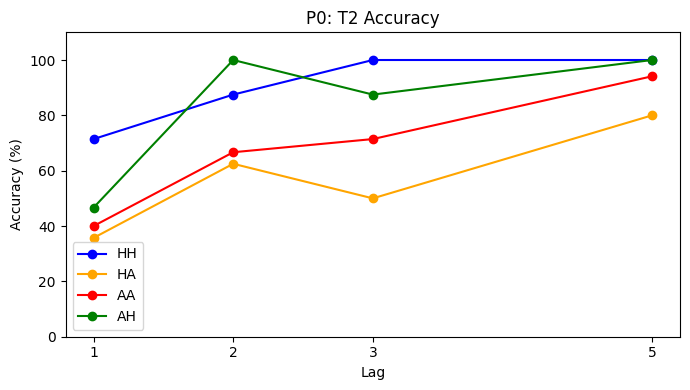

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


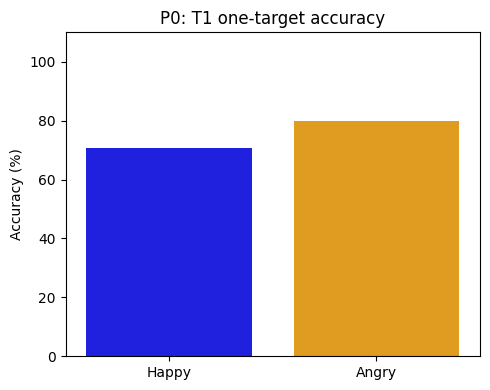

Processing P1


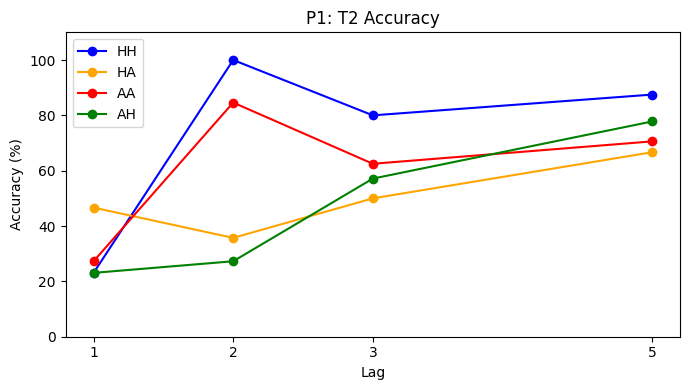

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


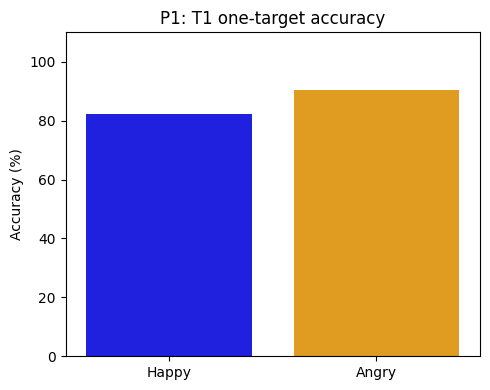

Processing P10


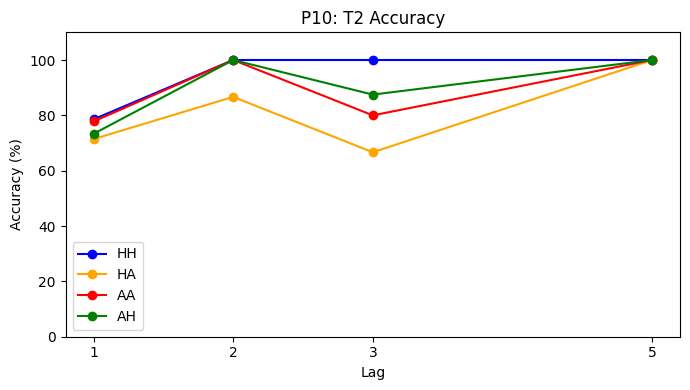

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


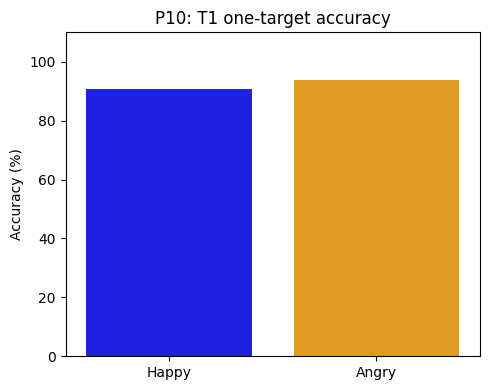

Processing P11


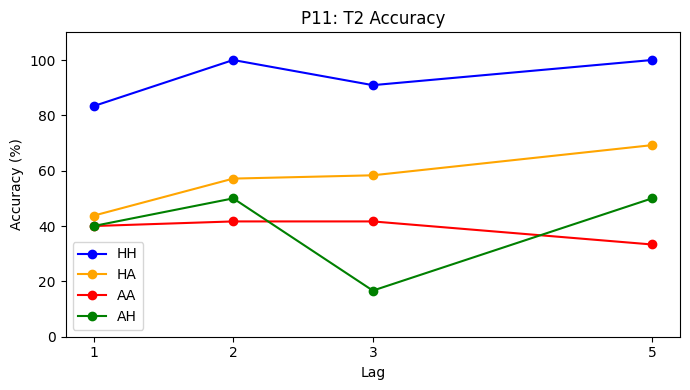

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


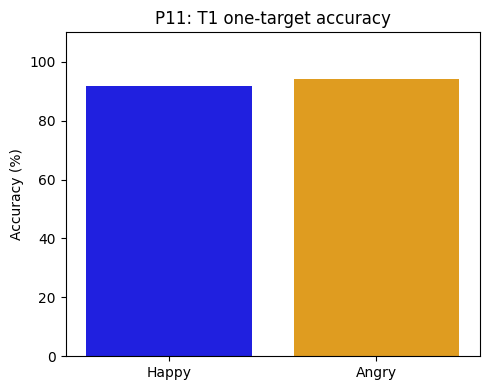

Processing P12


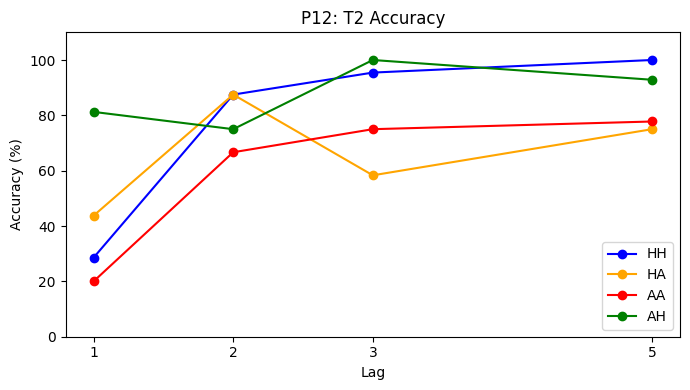

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


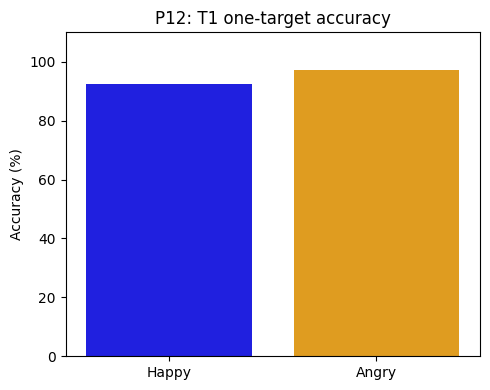

Processing P13


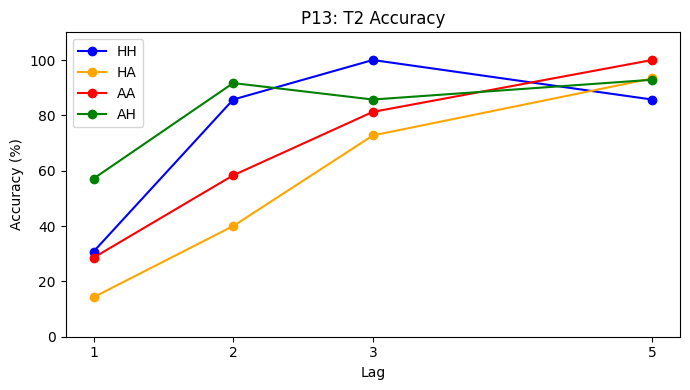

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


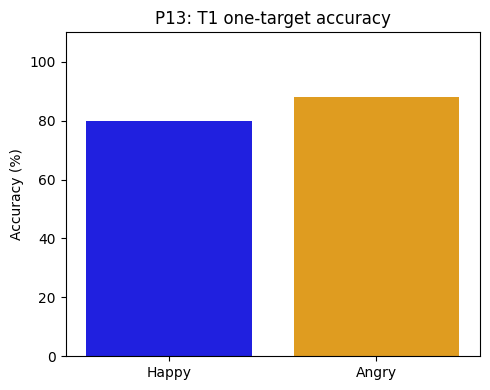

Processing P14


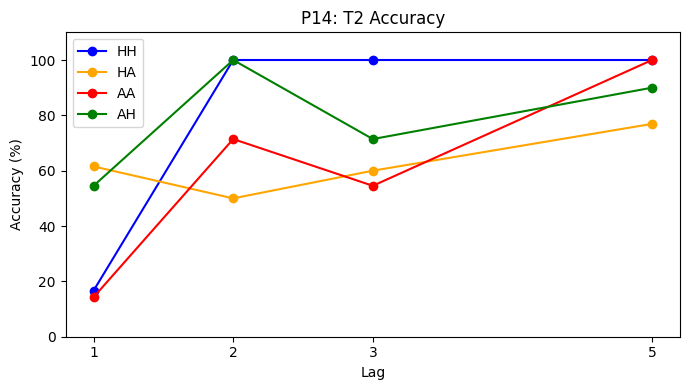

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


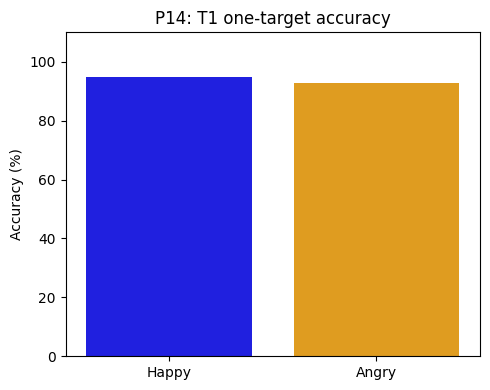

Processing P15


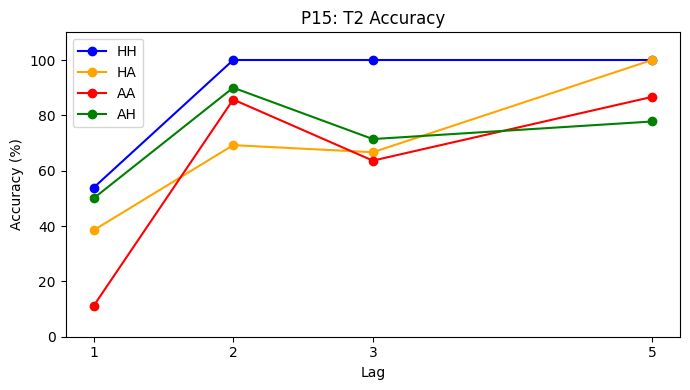

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


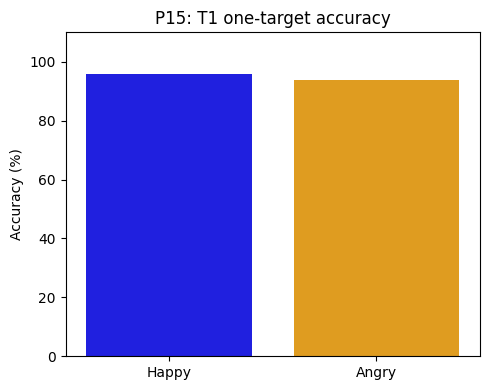

Processing P16


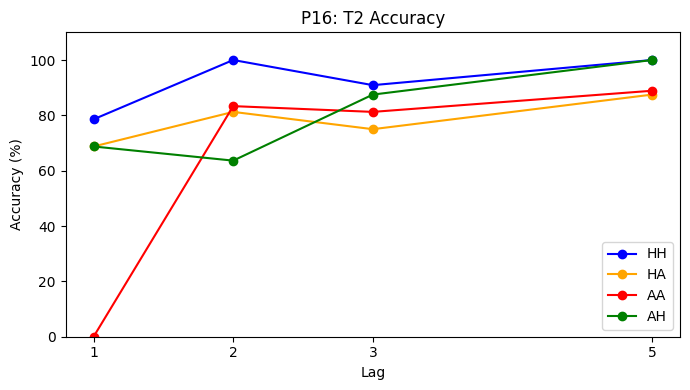

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


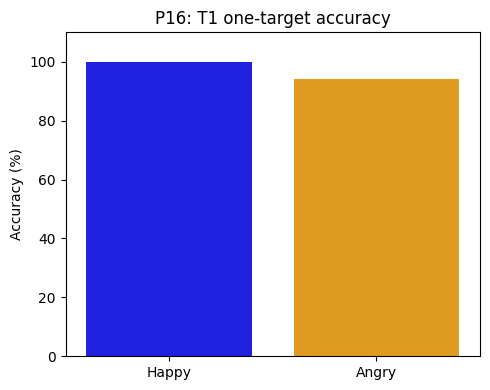

Processing P17


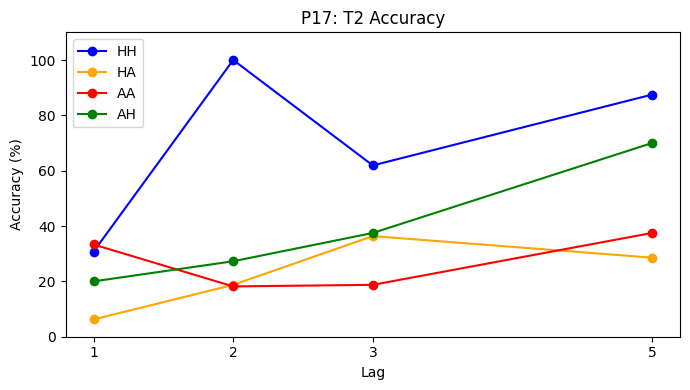

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


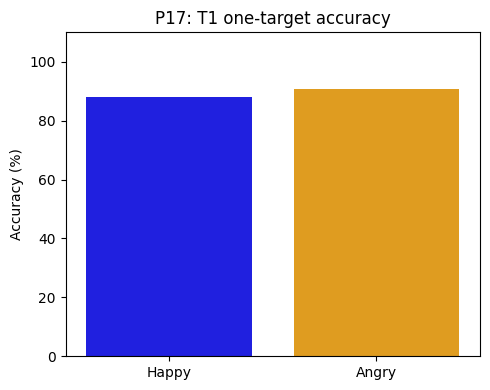

Processing P18


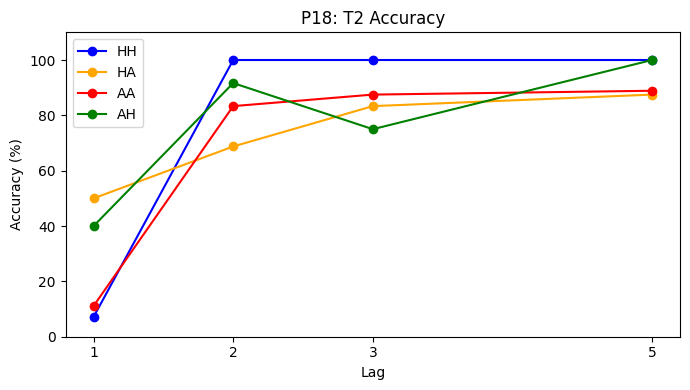

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


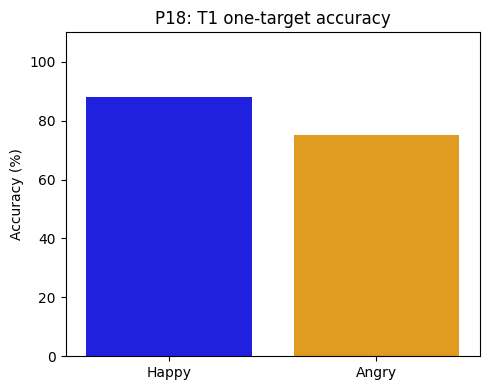

Processing P19


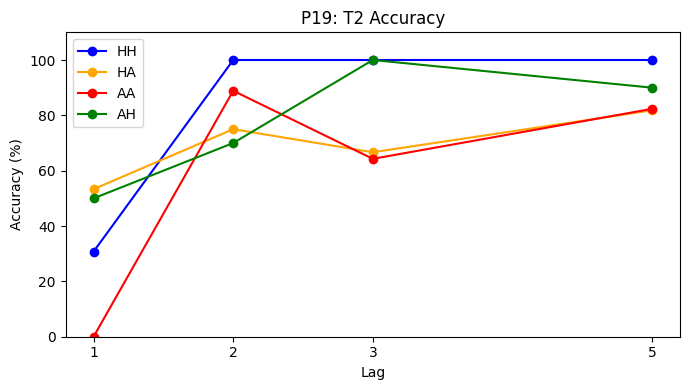

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


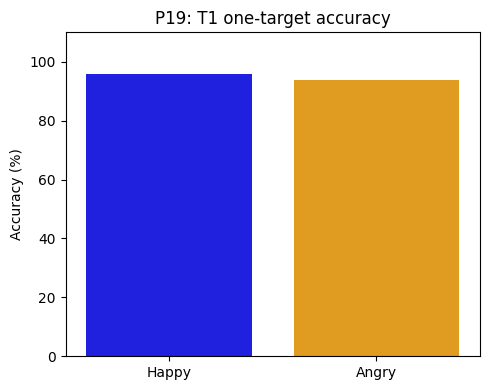

Processing P2


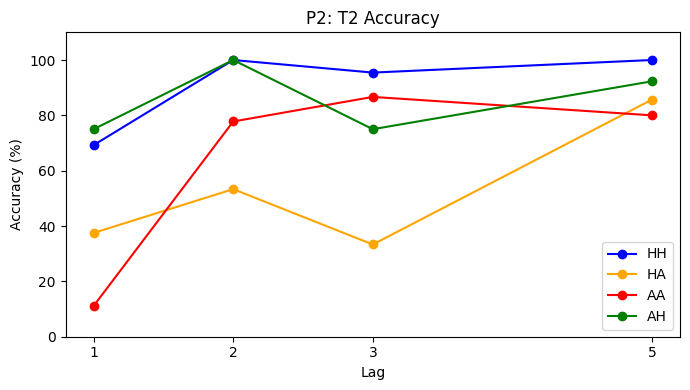

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


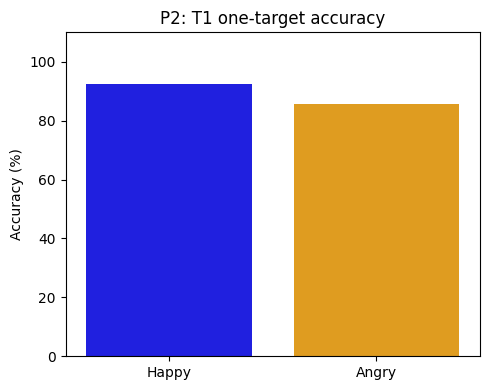

Processing P21


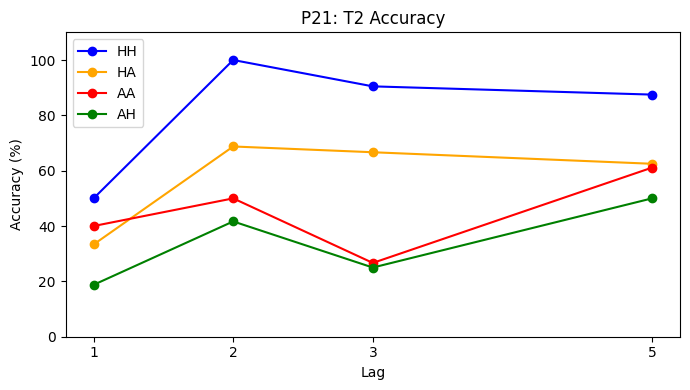

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


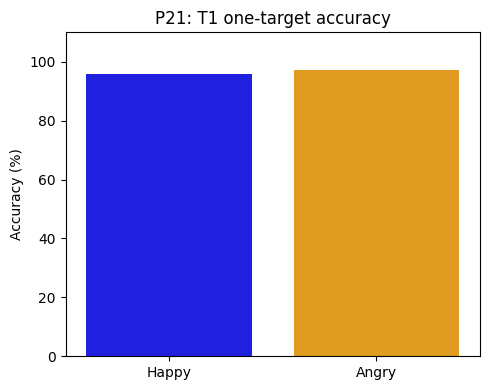

Processing P22


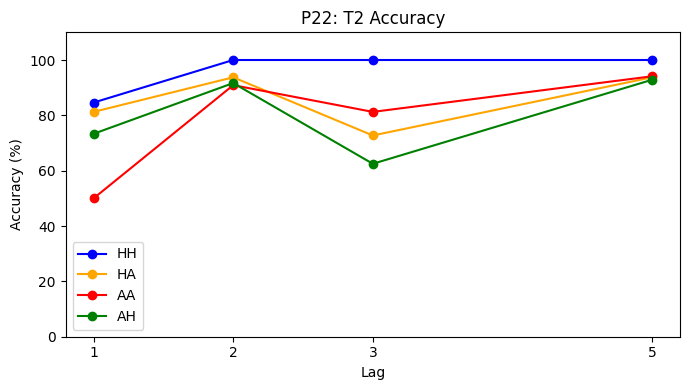

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


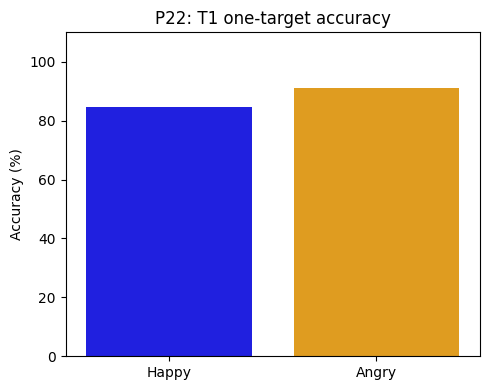

Processing P23


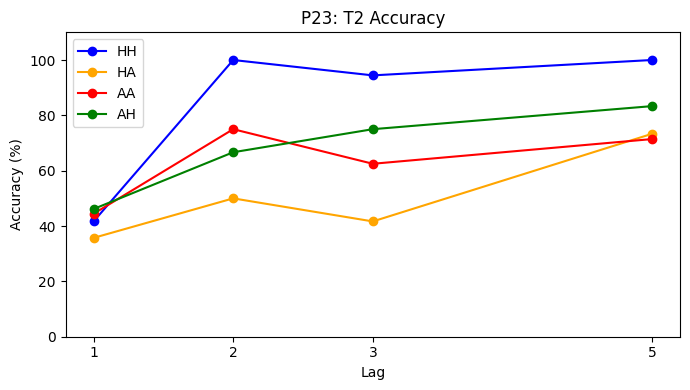

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


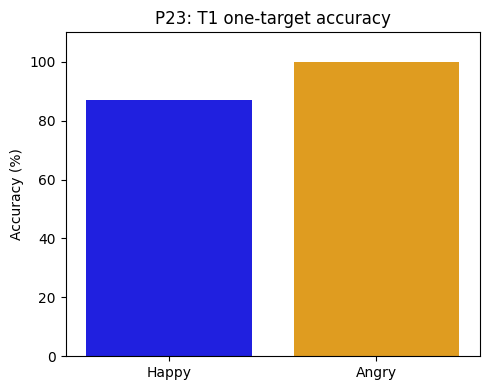

Processing P24


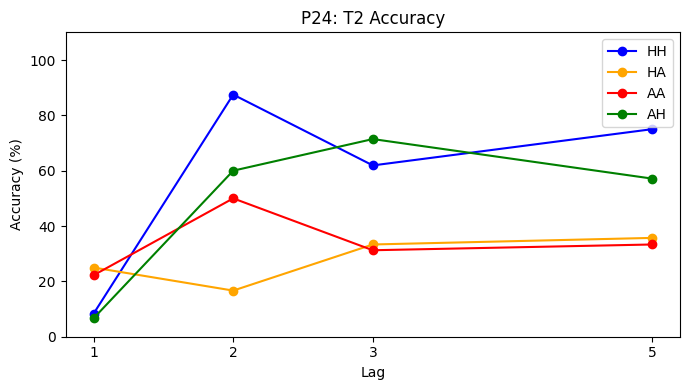

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


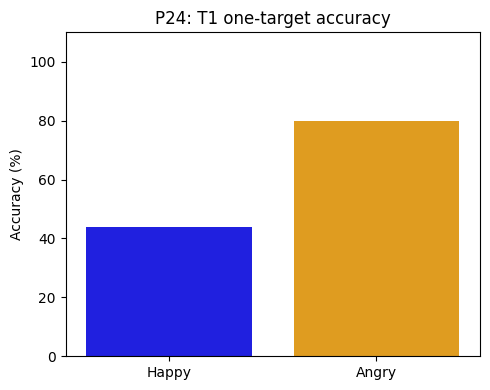

Processing P25


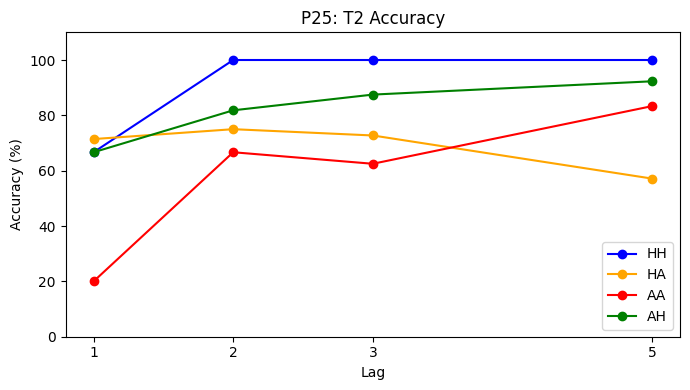

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


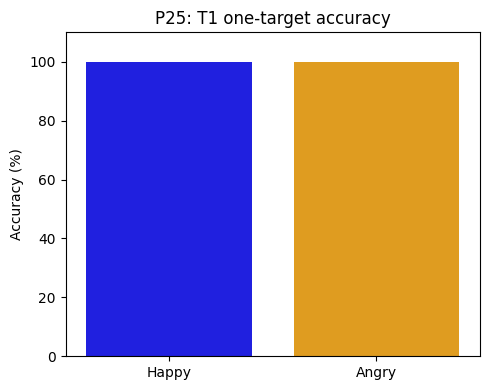

Processing P26


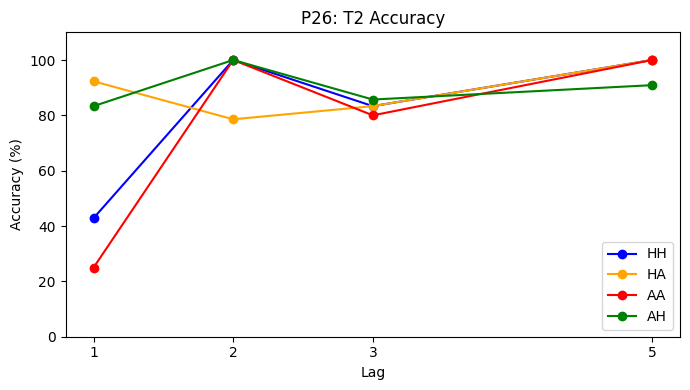

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


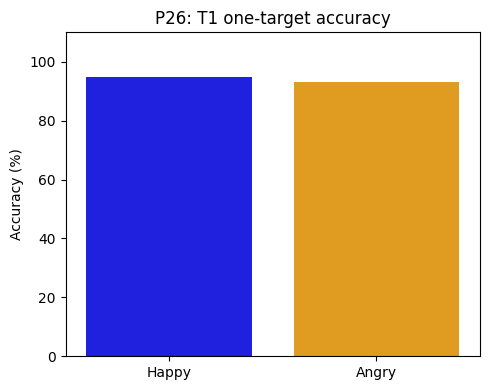

Processing P27


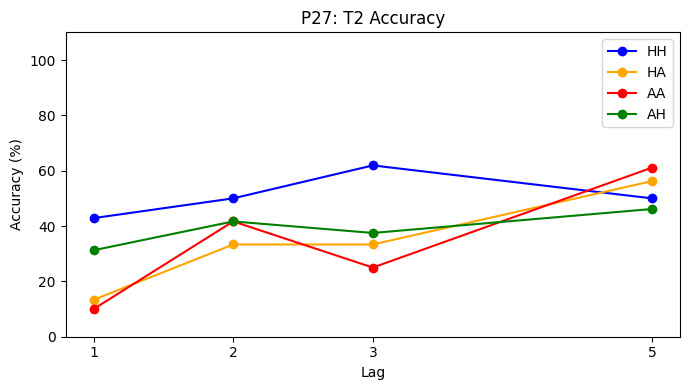

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


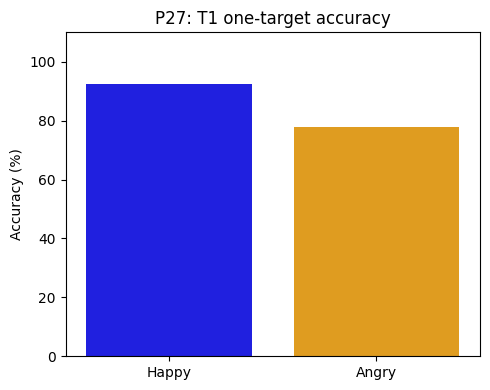

Processing P28


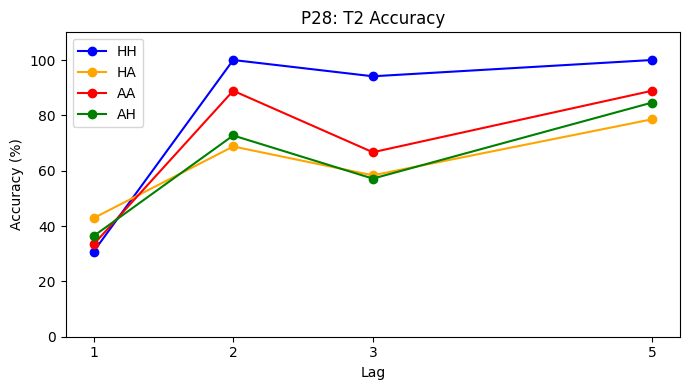

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


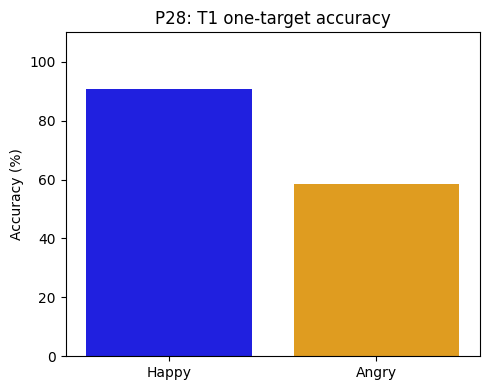

Processing P29


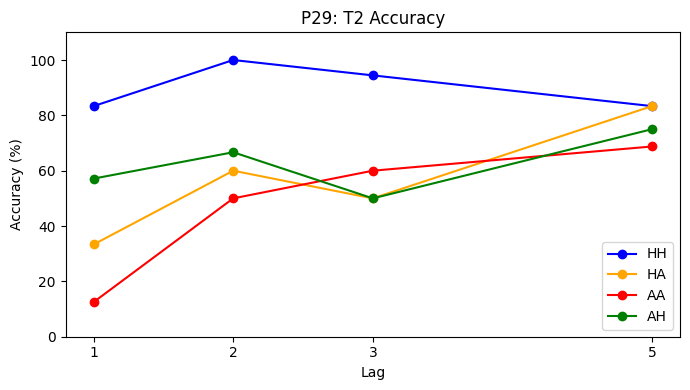

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


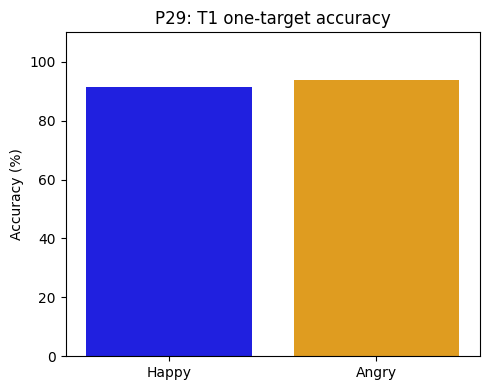

Processing P3


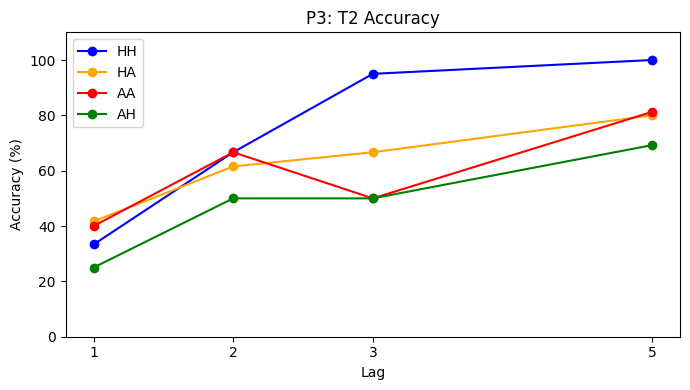

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


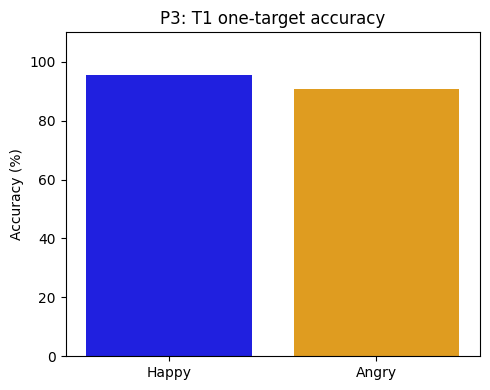

Processing P30


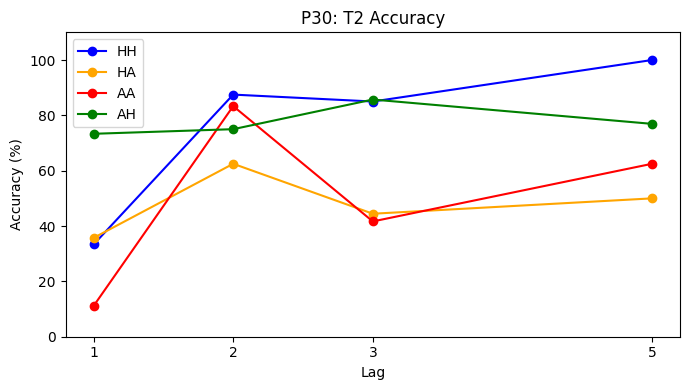

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


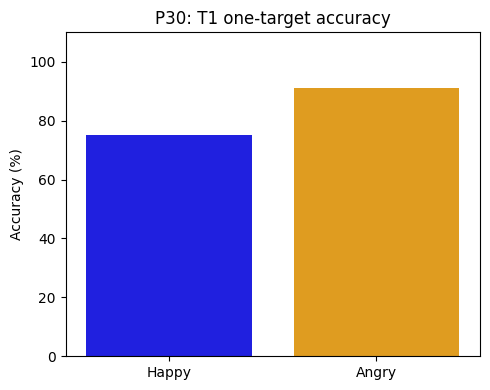

Processing P31


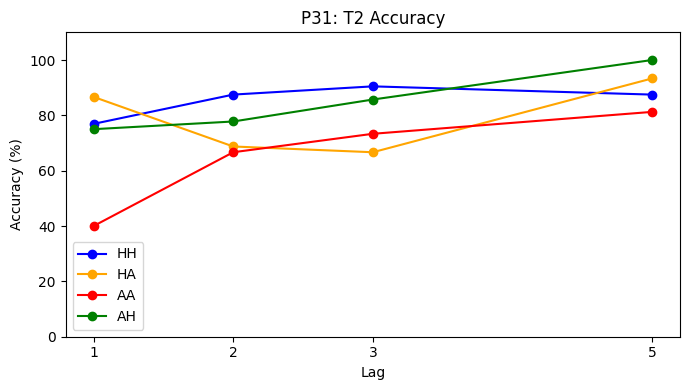

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


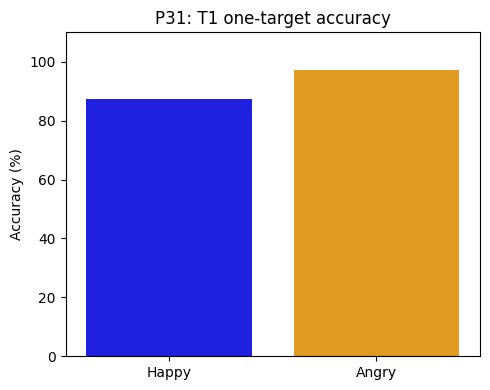

Processing P32


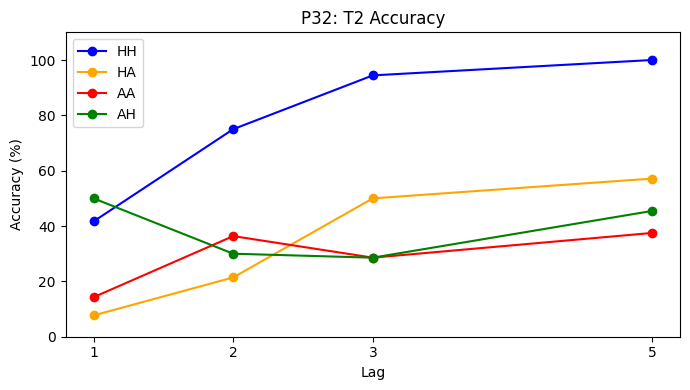

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


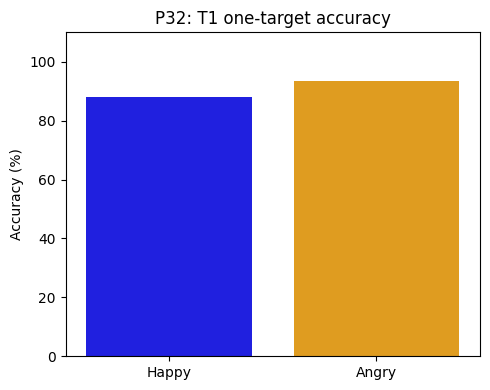

Processing P33


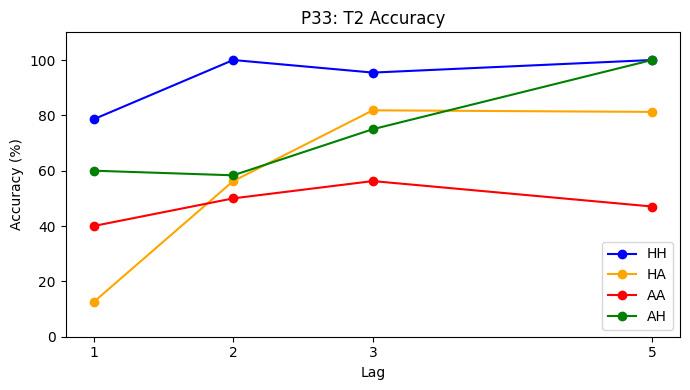

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


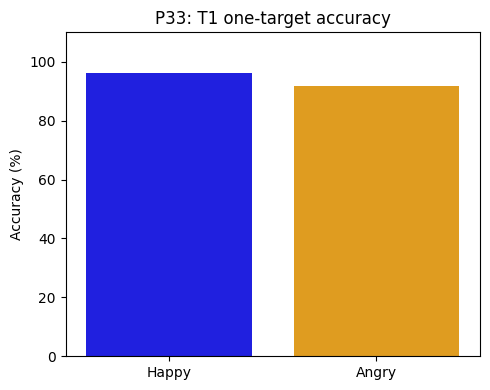

Processing P34


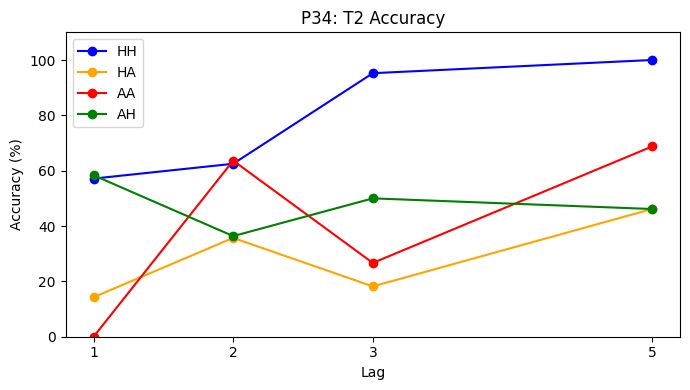

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


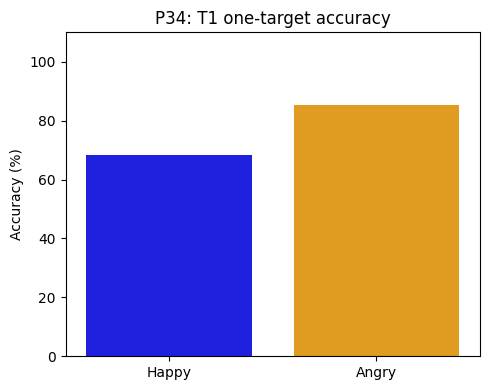

Processing P35


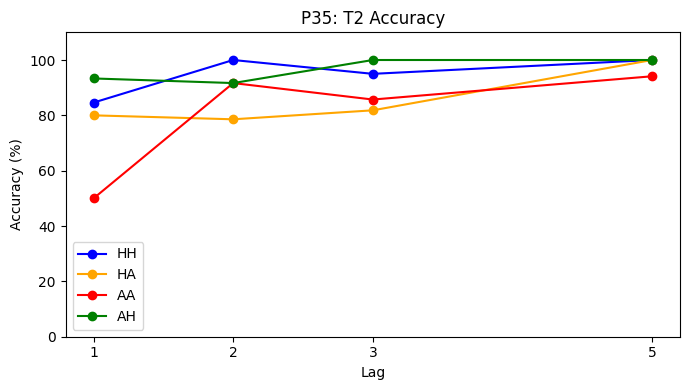

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


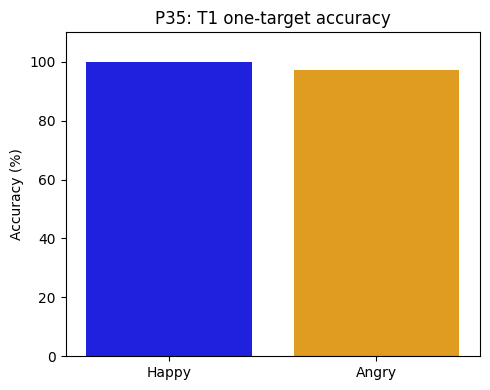

Processing P36


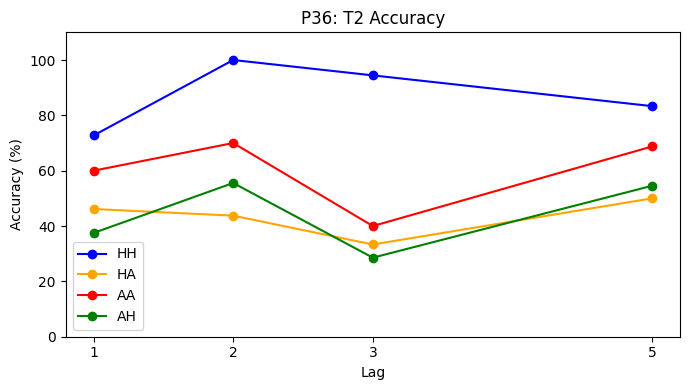

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


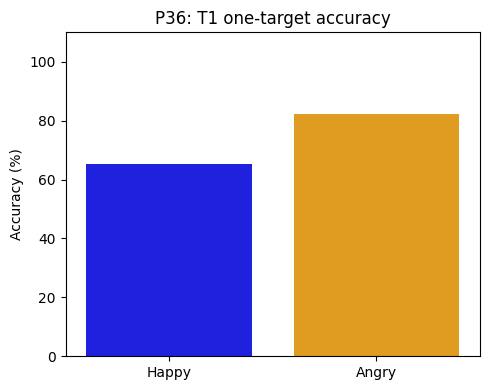

Processing P37


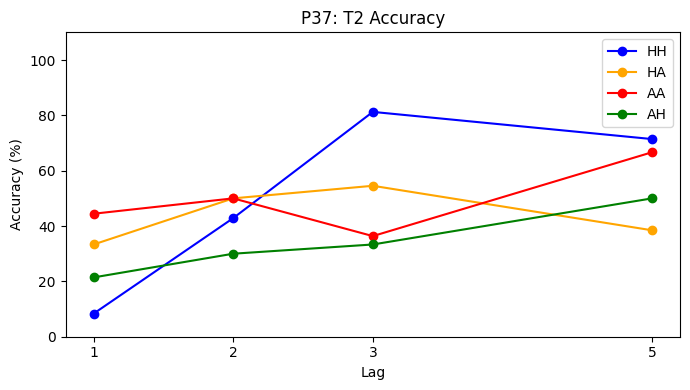

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


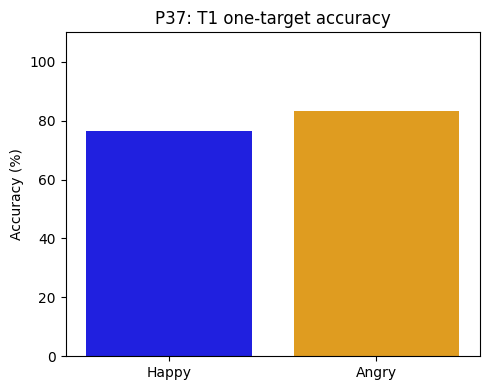

Processing P4


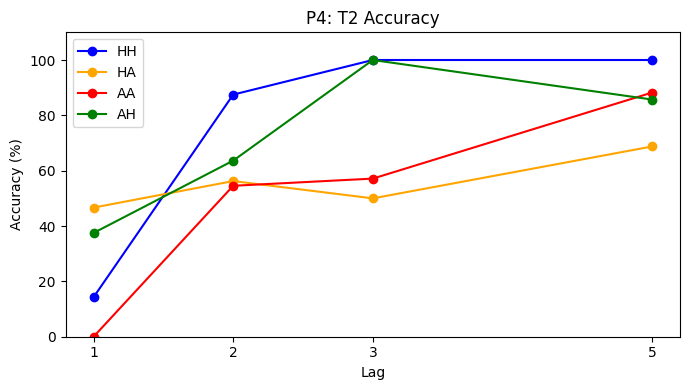

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


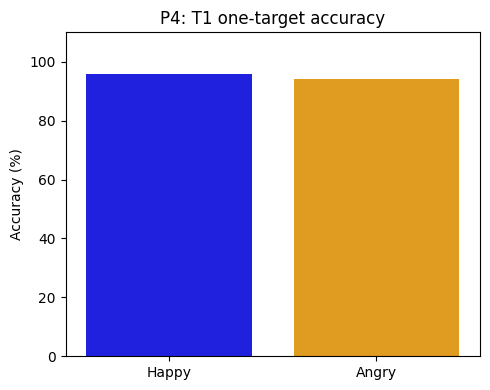

Processing P5


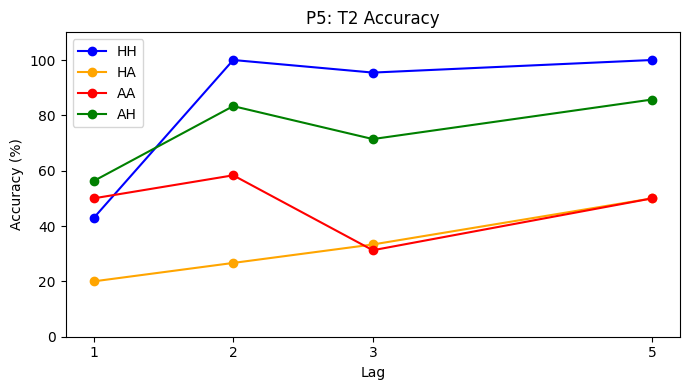

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


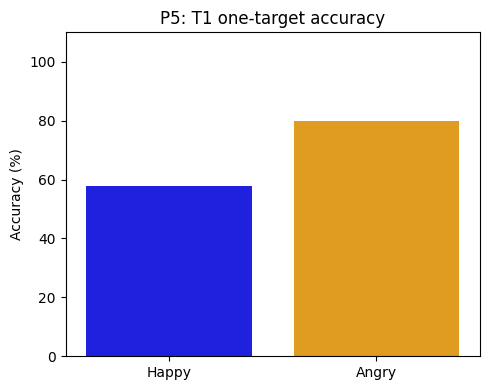

Processing P6


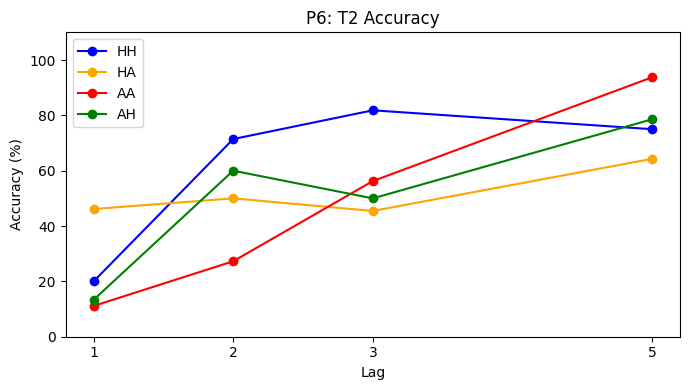

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


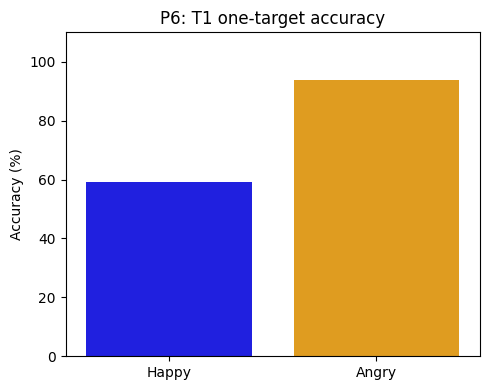

Processing P7


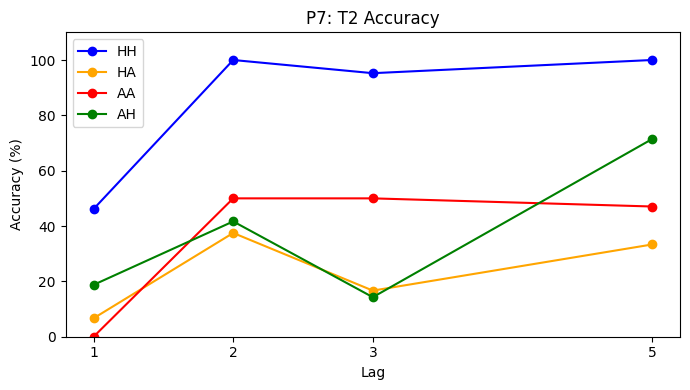

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


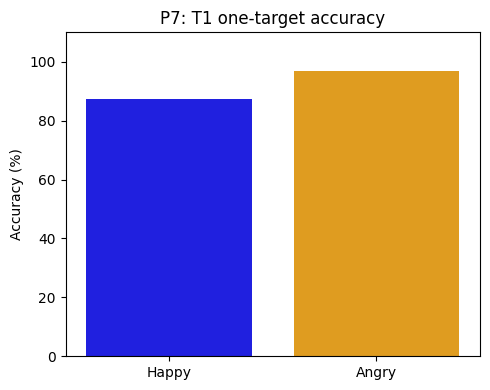

Processing P8


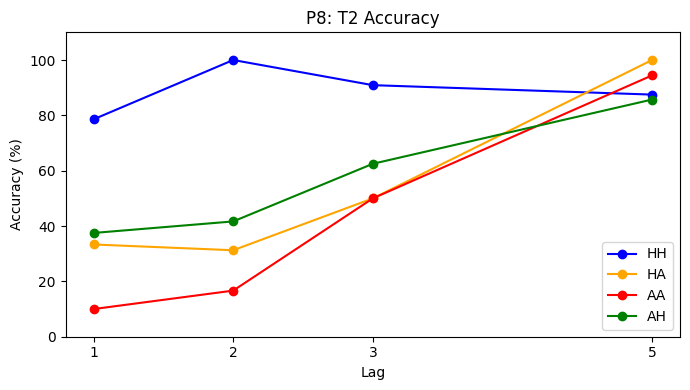

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


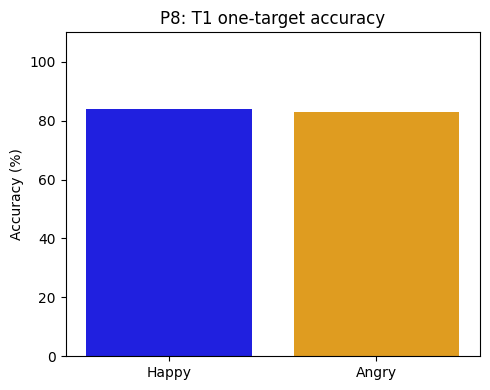

Processing P9


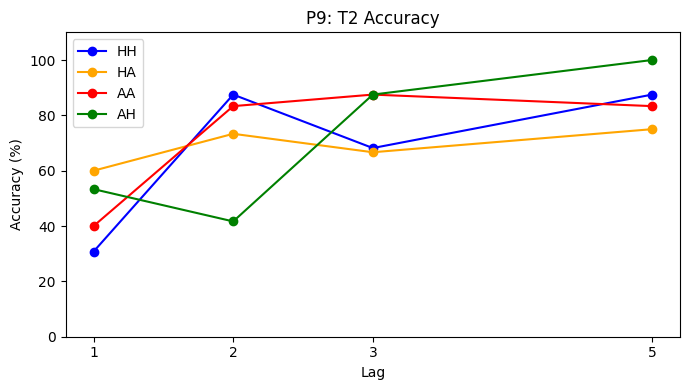

/tmp/ipykernel_2762/1658194445.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])


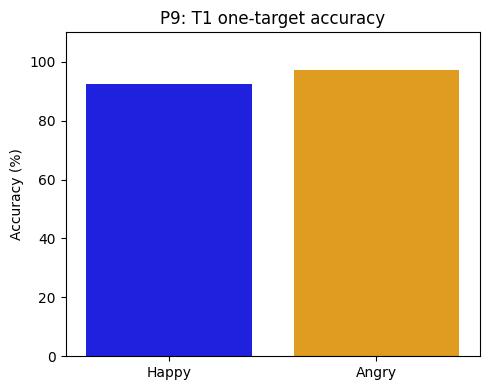

In [ ]:
import seaborn as sns

colors = {"HH":"blue","HA":"orange","AA":"red","AH":"green"}


group_HH = []
group_HA = []
group_AA = []
group_AH = []
group_T1_H = []
group_T1_A = []

# ---------- PER-PARTICIPANT PLOTS ----------
for pid, dm in sorted(all_dms.items()):
    print("Processing", pid)

    # Both-target accuracies (4 curves)
    acc_HH = acc_for_pair_bothkey(dm, "HH", "a", "a")
    acc_HA = acc_for_pair_bothkey(dm, "HA", "a", "l")
    acc_AA = acc_for_pair_bothkey(dm, "AA", "l", "l")
    acc_AH = acc_for_pair_bothkey(dm, "AH", "l", "a")

    # Save for group plot
    group_HH.append(acc_HH)
    group_HA.append(acc_HA)
    group_AA.append(acc_AA)
    group_AH.append(acc_AH)

    # ======== PLOT 1: Two-target per participant =========
    plt.figure(figsize=(7,4))
    plt.plot(LAGS, acc_HH, marker='o', label='HH', color=colors['HH'])
    plt.plot(LAGS, acc_HA, marker='o', label='HA', color=colors['HA'])
    plt.plot(LAGS, acc_AA, marker='o', label='AA', color=colors['AA'])
    plt.plot(LAGS, acc_AH, marker='o', label='AH', color=colors['AH'])
    plt.xticks(LAGS); plt.ylim(0,110)
    plt.xlabel("Lag"); plt.ylabel("Accuracy (%)")
    plt.title(f"{pid}: T2 Accuracy")
    plt.legend(); plt.tight_layout(); plt.show()

    # ======== Compute T1 one-target =========
    tot_h = (dm.two_targets==0) & (dm.pair=="HN")
    corr_h = tot_h & (dm.response_first_resp=="a") & (dm.second_resp=="a")
    acc_T1_H = Accuracy_Both_Target(dm, corr_h, tot_h)

    tot_a = (dm.two_targets==0) & (dm.pair=="AN")
    corr_a = tot_a & (dm.response_first_resp=="l") & (dm.second_resp=="a")
    acc_T1_A = Accuracy_Both_Target(dm, corr_a, tot_a)

    group_T1_H.append(acc_T1_H)
    group_T1_A.append(acc_T1_A)

    # ======== PLOT 2: T1 one-target per participant =========
    plt.figure(figsize=(5,4))
    sns.barplot(x=["Happy","Angry"], y=[acc_T1_H, acc_T1_A], palette=["blue","orange"])
    plt.ylim(0,110)
    plt.ylabel("Accuracy (%)")
    plt.title(f"{pid}: T1 one-target accuracy")
    plt.tight_layout(); plt.show()



## Save as csv ( accuracy data)

In [ ]:
import pandas as pd
import numpy as np

rows = []

for pid, dm in sorted(all_dms.items()):
    print("Extracting trials for", pid)

    n_trials = len(dm)

    two_targets = np.asarray(dm.two_targets)
    pair_arr    = np.asarray(dm.pair)


    T1_pos_arr = pd.to_numeric(np.asarray(dm.T1_pos), errors="coerce")
    T2_pos_arr = pd.to_numeric(np.asarray(dm.T2_pos), errors="coerce")

    resp1_arr   = np.asarray(dm.response_first_resp)
    resp2_arr   = np.asarray(dm.second_resp)
    resp3_arr   = np.asarray(dm.response_third_response)

    key_map = {"H": "a", "A": "l"}

    for i in range(n_trials):

        pair = pair_arr[i]


        if two_targets[i] == 1:

            T1 = pair[0]
            T2 = pair[1]

            if np.isnan(T1_pos_arr[i]) or np.isnan(T2_pos_arr[i]):
                continue

            lag = int(T2_pos_arr[i] - T1_pos_arr[i])

            if lag not in LAGS:
                continue

            correct = int(
                (resp1_arr[i] == key_map.get(T1)) and
                (resp2_arr[i] == "l") and
                (resp3_arr[i] == key_map.get(T2))
            )

            rows.append([pid, T1, T2, lag, correct])


        elif two_targets[i] == 0:

            T1 = pair[0]
            T2 = np.nan
            lag = np.nan

            correct = int(
                (resp1_arr[i] == key_map.get(T1)) and
                (resp2_arr[i] == "a")
            )

            rows.append([pid, T1, T2, lag, correct])



df_long = pd.DataFrame(
    rows,
    columns=["participant", "T1", "T2", "lag", "correct"]
)

df_long["lag"] = pd.to_numeric(df_long["lag"], errors="coerce")


print("\nLag distribution per participant (two-target only):")
print(
    df_long[df_long["T2"].notna()]
    .groupby("participant")["lag"]
    .unique()
)


out_csv = "/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/trialwise_accuracy.csv"
df_long.to_csv(out_csv, index=False)

print("\nSaved to:", out_csv)
print(df_long.head())

Extracting trials for P0
Extracting trials for P1
Extracting trials for P10
Extracting trials for P11
Extracting trials for P12
Extracting trials for P13
Extracting trials for P14
Extracting trials for P15
Extracting trials for P16
Extracting trials for P17
Extracting trials for P18
Extracting trials for P19
Extracting trials for P2
Extracting trials for P21
Extracting trials for P22
Extracting trials for P23
Extracting trials for P24
Extracting trials for P25
Extracting trials for P26
Extracting trials for P27
Extracting trials for P28
Extracting trials for P29
Extracting trials for P3
Extracting trials for P30
Extracting trials for P31
Extracting trials for P32
Extracting trials for P33
Extracting trials for P34
Extracting trials for P35
Extracting trials for P36
Extracting trials for P37
Extracting trials for P4
Extracting trials for P5
Extracting trials for P6
Extracting trials for P7
Extracting trials for P8
Extracting trials for P9

Lag distribution per participant (two-target on

## Mean accross participants

In [ ]:
# Participants to exclude
EXCLUDE = {"P36", "P6", "P24", "P25","P35"}

group_HH = []
group_HA = []
group_AA = []
group_AH = []
group_T1_H = []
group_T1_A = []

for pid, dm in sorted(all_dms.items()):

    if pid in EXCLUDE:
        print(f"Skipping {pid}")
        continue

    print(f"Including {pid}")

    # Both-target accuracies
    acc_HH = acc_for_pair_bothkey(dm, "HH", "a", "a")
    acc_HA = acc_for_pair_bothkey(dm, "HA", "a", "l")
    acc_AA = acc_for_pair_bothkey(dm, "AA", "l", "l")
    acc_AH = acc_for_pair_bothkey(dm, "AH", "l", "a")

    group_HH.append(acc_HH)
    group_HA.append(acc_HA)
    group_AA.append(acc_AA)
    group_AH.append(acc_AH)

    # T1 one-target
    tot_h = (dm.two_targets==0) & (dm.pair=="HN")
    corr_h = tot_h & (dm.response_first_resp=="a") & (dm.second_resp=="a")
    acc_T1_H = Accuracy_Both_Target(dm, corr_h, tot_h)

    tot_a = (dm.two_targets==0) & (dm.pair=="AN")
    corr_a = tot_a & (dm.response_first_resp=="l") & (dm.second_resp=="a")
    acc_T1_A = Accuracy_Both_Target(dm, corr_a, tot_a)

    group_T1_H.append(acc_T1_H)
    group_T1_A.append(acc_T1_A)


Including P0
Including P1
Including P10
Including P11
Including P12
Including P13
Including P14
Including P15
Including P16
Including P17
Including P18
Including P19
Including P2
Including P21
Including P22
Including P23
Skipping P24
Skipping P25
Including P26
Including P27
Including P28
Including P29
Including P3
Including P30
Including P31
Including P32
Including P33
Including P34
Skipping P35
Skipping P36
Including P37
Including P4
Including P5
Skipping P6
Including P7
Including P8
Including P9


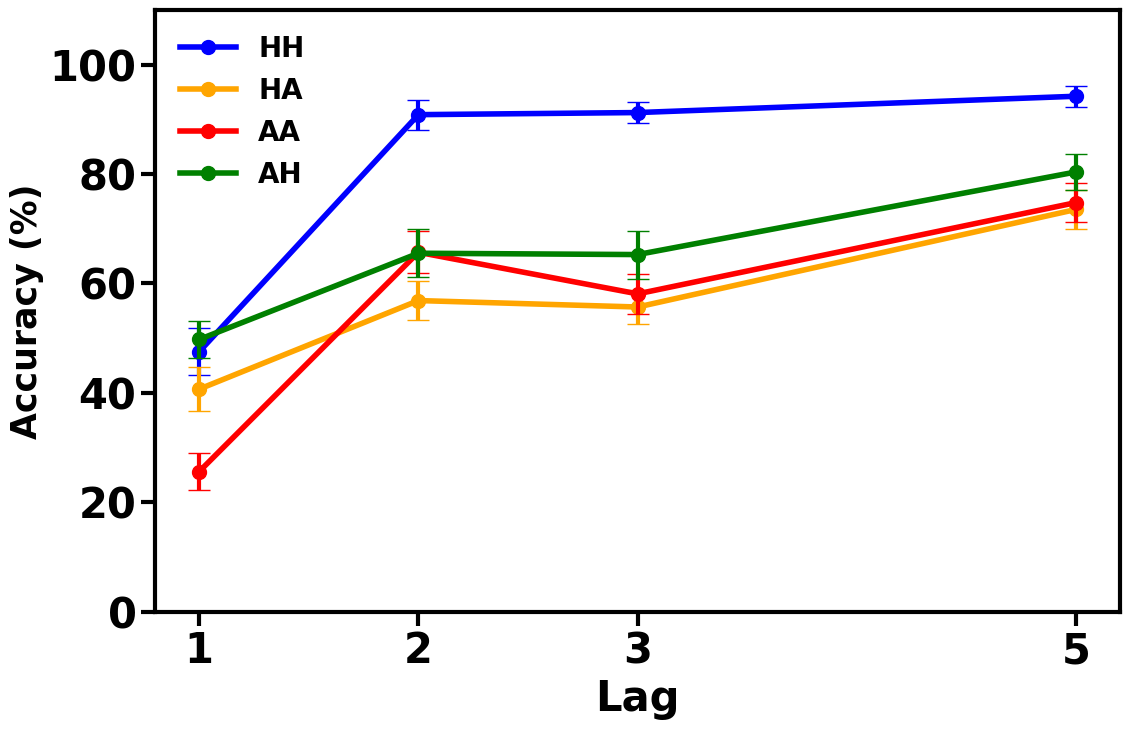

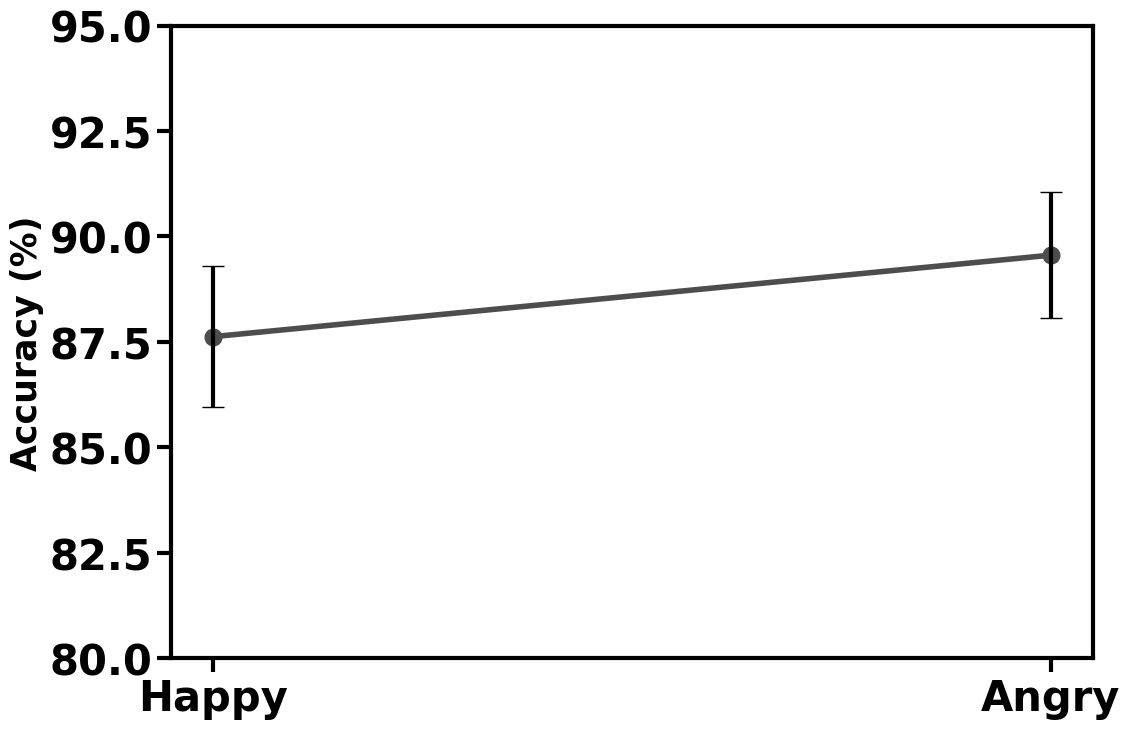

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 30,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

def mean_sem(arr):
    arr = np.array(arr, dtype=float)
    mean = np.nanmean(arr, axis=0)
    sem  = np.nanstd(arr, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(arr), axis=0))
    return mean, sem

mean_HH, sem_HH = mean_sem(group_HH)
mean_HA, sem_HA = mean_sem(group_HA)
mean_AA, sem_AA = mean_sem(group_AA)
mean_AH, sem_AH = mean_sem(group_AH)

fig, ax = plt.subplots(figsize=(12,8))

for pair, m, s in zip(["HH","HA","AA","AH"],
                      [mean_HH, mean_HA, mean_AA, mean_AH],
                      [sem_HH, sem_HA, sem_AA, sem_AH]):

    ax.plot(
        LAGS, m,
        marker='o',
        markersize=10,
        linewidth=4,
        color=colors[pair],
        label=f"{pair}"
    )

    ax.errorbar(
        LAGS, m, yerr=s,
        fmt='none',
        ecolor=colors[pair],
        elinewidth=3,
        capsize=8
    )

ax.set_xticks(LAGS)
ax.set_ylim(0,110)

ax.set_xlabel("Lag", fontsize=30, fontweight='bold')
ax.set_ylabel("Accuracy (%)", fontsize=25, fontweight='bold')
#ax.set_title("T2 Accuracy", fontsize=34, fontweight='bold')

ax.tick_params(axis='both', which='major', labelsize=30, width=3, length=10)

for spine in ax.spines.values():
    spine.set_linewidth(3)

ax.legend(fontsize=20, frameon=False)

plt.tight_layout()
plt.show()



mean_T1_H = np.nanmean(group_T1_H)
sem_T1_H  = np.nanstd(group_T1_H, ddof=1)/np.sqrt(len(group_T1_H))

mean_T1_A = np.nanmean(group_T1_A)
sem_T1_A  = np.nanstd(group_T1_A, ddof=1)/np.sqrt(len(group_T1_A))

x = np.array([0, 1])
labels = ["Happy", "Angry"]

fig, ax = plt.subplots(figsize=(12,8))

ax.plot(
    x,
    [mean_T1_H, mean_T1_A],
    marker='o',
    markersize=12,
    linewidth=4,
    color="#4d4d4d"
)

ax.errorbar(
    x,
    [mean_T1_H, mean_T1_A],
    yerr=[sem_T1_H, sem_T1_A],
    fmt='none',
    ecolor='black',
    elinewidth=3,
    capsize=8
)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=30, fontweight='bold')

ax.set_ylim(80,95)

ax.set_ylabel("Accuracy (%)", fontsize=25, fontweight='bold')
#ax.set_title("Accuracy (Single Target)", fontsize=34, fontweight='bold')

ax.tick_params(axis='both', which='major', labelsize=30, width=3, length=10)

for spine in ax.spines.values():
    spine.set_linewidth(3)

plt.tight_layout()
plt.show()

# Statistics on T2 detection


In [ ]:
!pip install pingouin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 1.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import pingouin as pg
import numpy as np

# =============================================================================
# SETTINGS
# =============================================================================

EXCLUDE_PARTICIPANTS = ["P36", "P6", "P24", "P25", "P35"]

csv_path = (
    "/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)"
    "/Participants_Data/trialwise_accuracy.csv"
)

ALPHA = 0.05

# =============================================================================
# LOAD DATA
# =============================================================================

df = pd.read_csv(csv_path)

if EXCLUDE_PARTICIPANTS:
    print("Excluding participants:", EXCLUDE_PARTICIPANTS)
    df = df[~df["participant"].isin(EXCLUDE_PARTICIPANTS)].copy()

print("\nFinal N participants:",
      df["participant"].nunique())

df["correct"] = pd.to_numeric(df["correct"], errors="coerce")


# =============================================================================
# HELPER FUNCTIONS
# =============================================================================

def get_p_column(aov):
    candidates = [
        "p-unc",
        "p_unc",
        "p-GG-corr",
        "p_GG_corr",
        "p-gg-corr",
        "p_gg_corr",
    ]

    for col in candidates:
        if col in aov.columns:
            return col

    raise KeyError(
        f"No p-value column found. Columns: {list(aov.columns)}"
    )


def shapiro_by_group(
        data,
        dv,
        group_cols
):
    """
    Run Shapiro-Wilk test separately for each condition.
    """

    print("\n" + "=" * 70)
    print("NORMALITY CHECK (SHAPIRO-WILK)")
    print("=" * 70)

    results = []

    grouped = data.groupby(group_cols)

    for name, subdf in grouped:

        values = subdf[dv].dropna()

        if len(values) < 3:
            continue

        sw = pg.normality(values)

        W = sw["W"].iloc[0]
        p = sw["pval"].iloc[0]
        normal = p > ALPHA

        print(
            f"{name} | "
            f"W = {W:.4f}, "
            f"p = {p:.4f}, "
            f"{'Normal' if normal else 'Non-normal'}"
        )

        results.append([
            name,
            W,
            p,
            normal
        ])

    return pd.DataFrame(
        results,
        columns=[
            "Condition",
            "W",
            "p",
            "Normal"
        ]
    )


# =============================================================================
# TWO TARGET ANALYSIS
# =============================================================================

df_two = df[
    df["T2"].fillna("") != ""
].copy()

df_two["pair"] = (
    df_two["T1"].astype(str)
    + df_two["T2"].astype(str)
)

df_two["lag"] = pd.to_numeric(
    df_two["lag"],
    errors="coerce"
)

df_two_agg = (
    df_two
    .groupby(
        ["participant", "pair", "lag"],
        as_index=False
    )["correct"]
    .mean()
)

print("\n")
print("=" * 70)
print("TWO-TARGET ANALYSIS")
print("=" * 70)

# -----------------------------------------------------------------------------
# Normality
# -----------------------------------------------------------------------------

normality_two = shapiro_by_group(
    df_two_agg,
    dv="correct",
    group_cols=["pair", "lag"]
)

n_non_normal = (~normality_two["Normal"]).sum()

print(
    f"\nNon-normal cells: "
    f"{n_non_normal}/{len(normality_two)}"
)

# -----------------------------------------------------------------------------
# RM ANOVA
# -----------------------------------------------------------------------------

print("\n")
print("=" * 70)
print("RM ANOVA: pair × lag")
print("=" * 70)

aov_two = pg.rm_anova(
    data=df_two_agg,
    dv="correct",
    within=["pair", "lag"],
    subject="participant",
    detailed=True
)

print(aov_two)

pcol_two = get_p_column(aov_two)

if (aov_two[pcol_two] < ALPHA).any():

    print(
        "\nSignificant effect detected."
        "\nRunning Bonferroni-corrected posthoc tests."
    )

    posthoc_two = pg.pairwise_tests(
        data=df_two_agg,
        dv="correct",
        within=["pair", "lag"],
        subject="participant",
        padjust="bonf"
    )

    print(posthoc_two)

else:

    print("\nNo significant main or interaction effects.")


# =============================================================================
# ONE TARGET ANALYSIS
# =============================================================================

df_one = df[
    df["T2"].fillna("") == ""
].copy()

df_one_agg = (
    df_one
    .groupby(
        ["participant", "T1"],
        as_index=False
    )["correct"]
    .mean()
)

print("\n")
print("=" * 70)
print("ONE-TARGET ANALYSIS")
print("=" * 70)

# -----------------------------------------------------------------------------
# Normality
# -----------------------------------------------------------------------------

normality_one = shapiro_by_group(
    df_one_agg,
    dv="correct",
    group_cols=["T1"]
)

n_non_normal = (~normality_one["Normal"]).sum()

print(
    f"\nNon-normal cells: "
    f"{n_non_normal}/{len(normality_one)}"
)

# -----------------------------------------------------------------------------
# RM ANOVA
# -----------------------------------------------------------------------------

print("\n")
print("=" * 70)
print("RM ANOVA: H vs A")
print("=" * 70)

aov_one = pg.rm_anova(
    data=df_one_agg,
    dv="correct",
    within="T1",
    subject="participant",
    detailed=True
)

print(aov_one)

pcol_one = get_p_column(aov_one)

if (aov_one[pcol_one] < ALPHA).any():

    print(
        "\nSignificant effect detected."
        "\nRunning Bonferroni-corrected posthoc."
    )

    posthoc_one = pg.pairwise_tests(
        data=df_one_agg,
        dv="correct",
        within="T1",
        subject="participant",
        padjust="bonf"
    )

    print(posthoc_one)

else:

    print("\nNo significant H vs A difference.")


# =============================================================================
# OPTIONAL: NONPARAMETRIC CHECK FOR H vs A
# =============================================================================

print("\n")
print("=" * 70)
print("OPTIONAL WILCOXON TEST (H vs A)")
print("=" * 70)

wide_one = df_one_agg.pivot(
    index="participant",
    columns="T1",
    values="correct"
)

if wide_one.shape[1] == 2:

    cols = list(wide_one.columns)

    wilcox = pg.wilcoxon(
        wide_one[cols[0]],
        wide_one[cols[1]]
    )

    print(
        f"Comparison: {cols[0]} vs {cols[1]}"
    )
    print(wilcox)

Excluding participants: ['P36', 'P6', 'P24', 'P25', 'P35']

Final N participants: 32


TWO-TARGET ANALYSIS

NORMALITY CHECK (SHAPIRO-WILK)
('AA', np.float64(1.0)) | W = 0.9207, p = 0.0217, Non-normal
('AA', np.float64(2.0)) | W = 0.9564, p = 0.2189, Normal
('AA', np.float64(3.0)) | W = 0.9411, p = 0.0804, Normal
('AA', np.float64(5.0)) | W = 0.9258, p = 0.0299, Non-normal
('AH', np.float64(1.0)) | W = 0.9515, p = 0.1590, Normal
('AH', np.float64(2.0)) | W = 0.9201, p = 0.0210, Non-normal
('AH', np.float64(3.0)) | W = 0.9317, p = 0.0437, Non-normal
('AH', np.float64(5.0)) | W = 0.8602, p = 0.0007, Non-normal
('HA', np.float64(1.0)) | W = 0.9492, p = 0.1364, Normal
('HA', np.float64(2.0)) | W = 0.9740, p = 0.6173, Normal
('HA', np.float64(3.0)) | W = 0.9563, p = 0.2166, Normal
('HA', np.float64(5.0)) | W = 0.9397, p = 0.0735, Normal
('HH', np.float64(1.0)) | W = 0.9216, p = 0.0230, Non-normal
('HH', np.float64(2.0)) | W = 0.6556, p = 0.0000, Non-normal
('HH', np.float64(3.0)) | W = 0.760

/usr/local/lib/python3.12/dist-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


       Source         SS  ddof1  ddof2        MS           F         p_unc  \
0        pair   5.166222      3     93  1.722074   40.759364  6.610506e-17   
1         lag  10.978394      3     93  3.659465  152.842414  7.981333e-36   
2  pair * lag   1.449802      9    279  0.161089    9.240634  2.880070e-12   

      p_GG_corr       ng2       eps  
0  1.922064e-14  0.209911  0.831511  
1  1.140491e-24  0.360850  0.665988  
2  7.889580e-07  0.069385  0.469620  

Significant effect detected.
Running Bonferroni-corrected posthoc tests.
      Contrast pair    A    B Paired Parametric          T   dof alternative  \
0         pair    -   AA   AH   True       True  -4.175598  31.0   two-sided   
1         pair    -   AA   HA   True       True  -0.368716  31.0   two-sided   
2         pair    -   AA   HH   True       True  -9.057432  31.0   two-sided   
3         pair    -   AH   HA   True       True   3.291931  31.0   two-sided   
4         pair    -   AH   HH   True       True  -5.226518  3

In [ ]:
import numpy as np
import pandas as pd
import pingouin as pg

EXCLUDE_PARTICIPANTS = ["P36", "P6", "P24", "P25", "P35"]

csv_path = "/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/trialwise_accuracy.csv"

df = pd.read_csv(csv_path)

if EXCLUDE_PARTICIPANTS:
    print("Excluding participants:", EXCLUDE_PARTICIPANTS)
    df = df[~df["participant"].isin(EXCLUDE_PARTICIPANTS)].copy()

print("Final N participants:", df["participant"].nunique())

df["correct"] = pd.to_numeric(df["correct"], errors="coerce")


def get_first_existing_column(table, candidates, table_name="table"):
    for col in candidates:
        if col in table.columns:
            return col
    raise KeyError(
        f"No recognized column found in {table_name}. "
        f"Available columns: {list(table.columns)}"
    )


def get_anova_p_column(aov):
    return get_first_existing_column(
        aov,
        [
            "p-unc",
            "p_unc",
            "p-GG-corr",
            "p_GG_corr",
            "p-gg-corr",
            "p_gg_corr",
        ],
        table_name="ANOVA result"
    )


def get_ttest_p_column(tt):
    return get_first_existing_column(
        tt,
        [
            "p-val",
            "p_val",
            "p",
            "p-unc",
            "p_unc",
        ],
        table_name="t-test result"
    )


def get_ttest_t_column(tt):
    return get_first_existing_column(
        tt,
        [
            "T",
            "t",
        ],
        table_name="t-test result"
    )



df_two = df[df["T2"].fillna("") != ""].copy()

df_two["pair"] = df_two["T1"].astype(str) + df_two["T2"].astype(str)
df_two["lag"] = pd.to_numeric(df_two["lag"], errors="coerce")

df_two_agg = (
    df_two
    .groupby(["participant", "pair", "lag"], as_index=False)["correct"]
    .mean()
)

print("\n==========================================")
print("TWO-TARGET RM ANOVA (pair × lag)")
print("==========================================")

aov_two = pg.rm_anova(
    data=df_two_agg,
    dv="correct",
    within=["pair", "lag"],
    subject="participant",
    detailed=True
)

print(aov_two)

pcol_two = get_anova_p_column(aov_two)
alpha = 0.05

if (aov_two[pcol_two] < alpha).any():
    print("\nSignificant effect detected -> Running posthoc tests")

    posthoc_two = pg.pairwise_tests(
        data=df_two_agg,
        dv="correct",
        within=["pair", "lag"],
        subject="participant",
        padjust="bonf"
    )
    print(posthoc_two)
else:
    print("\nNo significant main or interaction effects.")

print("\n==========================================")
print("ONE-TARGET PAIRED T-TEST (H vs A)")
print("==========================================")

# --- Recreate one-target dataset (SAFE) ---
df_one = df[df["T2"].fillna("") == ""].copy()

df_one_agg = (
    df_one
    .groupby(["participant", "T1"], as_index=False)["correct"]
    .mean()
)

# --- Convert to wide format ---
df_wide = df_one_agg.pivot(
    index="participant",
    columns="T1",
    values="correct"
)

print("Available conditions:", df_wide.columns.tolist())

if not {"H", "A"}.issubset(df_wide.columns):
    raise ValueError(f"Expected 'H' and 'A', but found {df_wide.columns.tolist()}")

dH = df_wide["H"]
dA = df_wide["A"]

valid = ~(dH.isna() | dA.isna())
dH_valid = dH[valid]
dA_valid = dA[valid]

print(f"N (paired): {len(dH_valid)}")

ttest_one = pg.ttest(dH_valid, dA_valid, paired=True)
print(ttest_one)

tcol = get_ttest_t_column(ttest_one)
pcol = get_ttest_p_column(ttest_one)

t = ttest_one[tcol].iloc[0]
p = ttest_one[pcol].iloc[0]

diff = dH_valid - dA_valid
diff_sd = np.std(diff, ddof=1)

dz = np.nan if np.isclose(diff_sd, 0) else np.mean(diff) / diff_sd

alpha = 0.05
sig = "SIGNIFICANT" if p < alpha else "n.s."

print(
    f"\nH vs A: t = {t:.3f}, "
    f"p = {p:.4f}, "
    f"Cohen's dz = {dz:.3f} --> {sig}"
)


print("Lag 1 vs Other Lags (within each emotion pair)")
print("Paired t-tests, Bonferroni corrected")
print("====================================================")

pairs = sorted(df_two_agg["pair"].dropna().unique())

for pair in pairs:

    df_pair = df_two_agg[df_two_agg["pair"] == pair].copy()

    df_wide = df_pair.pivot(
        index="participant",
        columns="lag",
        values="correct"
    )

    if 1 not in df_wide.columns:
        print(f"\n--- {pair} ---")
        print("Lag 1 not found. Skipping.")
        continue

    comparisons = []
    pvals = []
    tvals = []
    effect_sizes = []

    for lag in sorted(df_wide.columns):
        if lag == 1:
            continue

        d1 = df_wide[1]
        d2 = df_wide[lag]

        valid = ~(d1.isna() | d2.isna())
        d1_valid = d1[valid]
        d2_valid = d2[valid]

        if len(d1_valid) < 5:
            continue

        test = pg.ttest(d1_valid, d2_valid, paired=True)

        tcol = get_ttest_t_column(test)
        pcol = get_ttest_p_column(test)

        t = test[tcol].iloc[0]
        p = test[pcol].iloc[0]

        diff = d1_valid - d2_valid
        diff_sd = np.std(diff, ddof=1)

        if np.isclose(diff_sd, 0) or np.isnan(diff_sd):
            dz = np.nan
        else:
            dz = np.mean(diff) / diff_sd

        comparisons.append((1, lag))
        tvals.append(t)
        pvals.append(p)
        effect_sizes.append(dz)

    print(f"\n--- {pair} ---")

    if len(pvals) == 0:
        print("No valid lag comparisons.")
        continue

    reject, pvals_corr = pg.multicomp(pvals, method="bonf")[:2]

    for (l1, l2), t, p_unc, p_corr, dz in zip(
        comparisons,
        tvals,
        pvals,
        pvals_corr,
        effect_sizes
    ):
        sig = "SIGNIFICANT" if p_corr < alpha else "n.s."

        print(
            f"Lag {l1} vs {l2}: "
            f"t = {t:.3f}, "
            f"p-unc = {p_unc:.4f}",
            f"p-bonf = {p_corr:.4f}, "
            f"Cohen's dz = {dz:.3f} --> {sig}"
        )

Excluding participants: ['P36', 'P6', 'P24', 'P25', 'P35']
Final N participants: 32

TWO-TARGET RM ANOVA (pair × lag)
       Source         SS  ddof1  ddof2        MS           F         p_unc  \
0        pair   5.166222      3     93  1.722074   40.759364  6.610506e-17   
1         lag  10.978394      3     93  3.659465  152.842414  7.981333e-36   
2  pair * lag   1.449802      9    279  0.161089    9.240634  2.880070e-12   

      p_GG_corr       ng2       eps  
0  1.922064e-14  0.209911  0.831511  
1  1.140491e-24  0.360850  0.665988  
2  7.889580e-07  0.069385  0.469620  

Significant effect detected -> Running posthoc tests


/usr/local/lib/python3.12/dist-packages/pingouin/distribution.py:514: UserWarning: Epsilon values might be innaccurate in two-way repeated measures design where each  factor has more than 2 levels. Please  double-check your results.
  warnings.warn(


      Contrast pair    A    B Paired Parametric          T   dof alternative  \
0         pair    -   AA   AH   True       True  -4.175598  31.0   two-sided   
1         pair    -   AA   HA   True       True  -0.368716  31.0   two-sided   
2         pair    -   AA   HH   True       True  -9.057432  31.0   two-sided   
3         pair    -   AH   HA   True       True   3.291931  31.0   two-sided   
4         pair    -   AH   HH   True       True  -5.226518  31.0   two-sided   
5         pair    -   HA   HH   True       True  -8.409083  31.0   two-sided   
6          lag    -  1.0  2.0   True       True -12.582664  31.0   two-sided   
7          lag    -  1.0  3.0   True       True -11.006458  31.0   two-sided   
8          lag    -  1.0  5.0   True       True -17.522754  31.0   two-sided   
9          lag    -  2.0  3.0   True       True   1.326184  31.0   two-sided   
10         lag    -  2.0  5.0   True       True  -6.805331  31.0   two-sided   
11         lag    -  3.0  5.0   True    

#  T1 accuracy as the function of the T2 lag

Processing P0


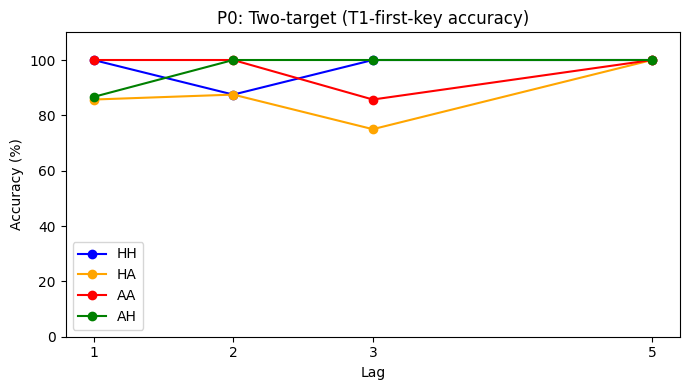

Processing P1


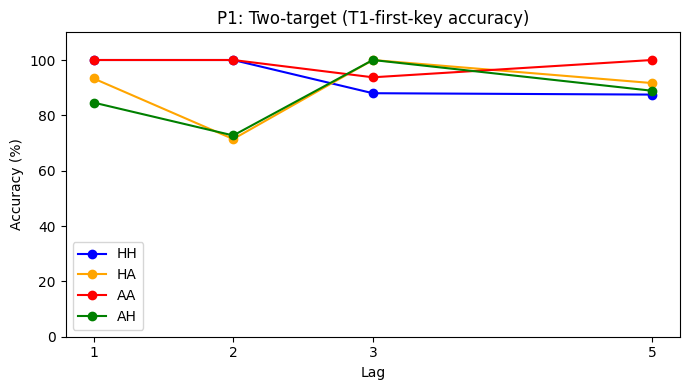

Processing P10


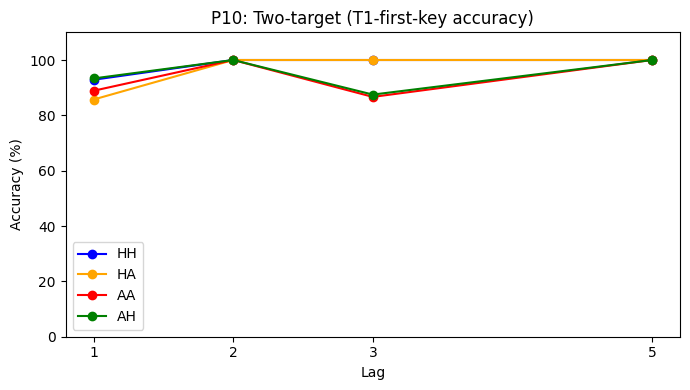

Processing P11


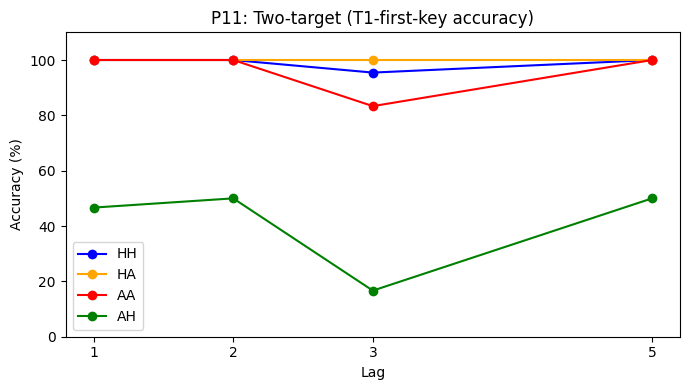

Processing P12


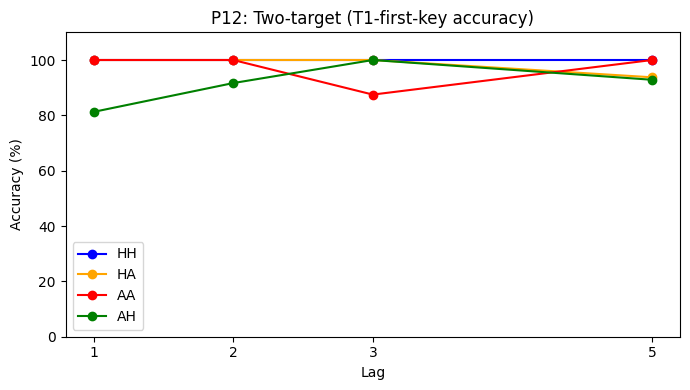

Processing P13


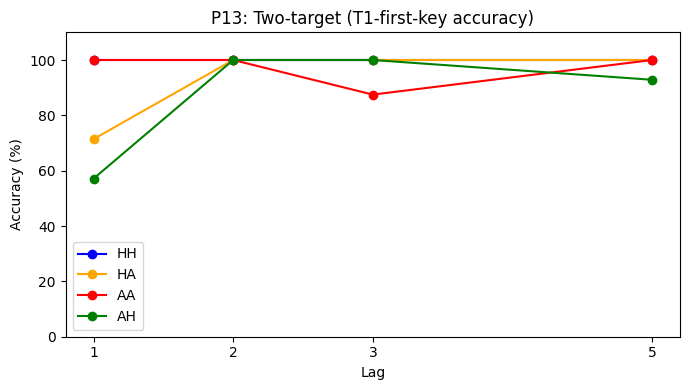

Processing P14


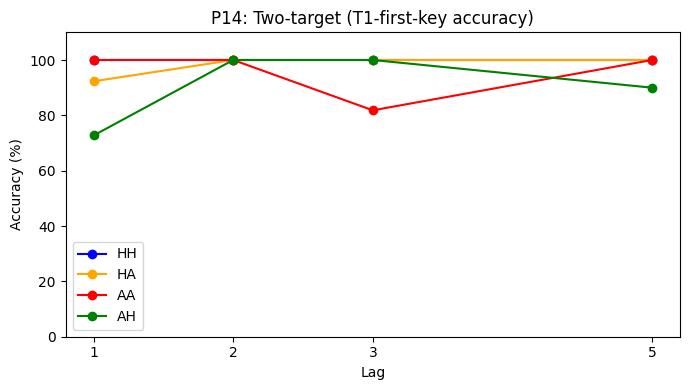

Processing P15


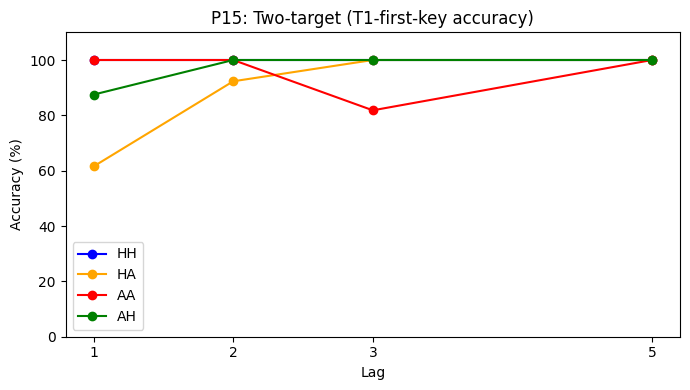

Processing P16


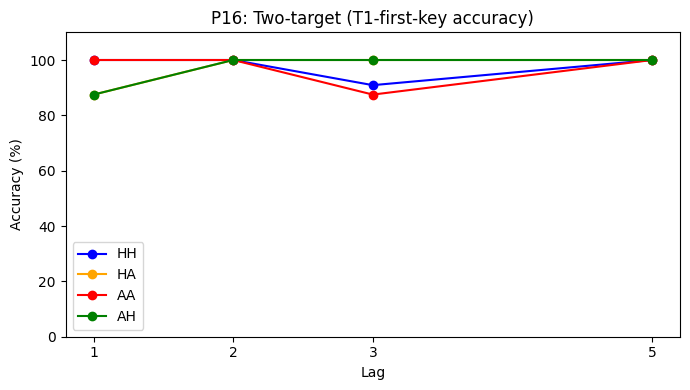

Processing P17


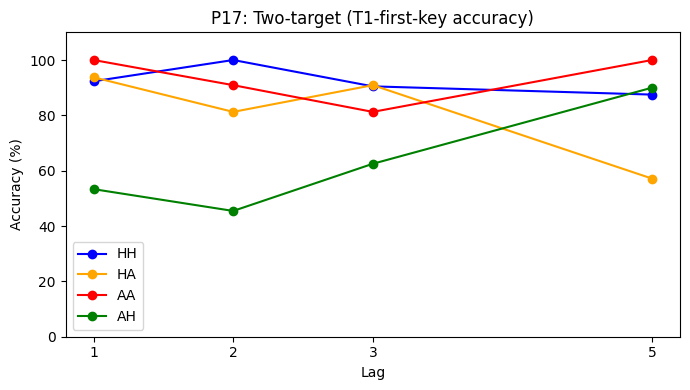

Processing P18


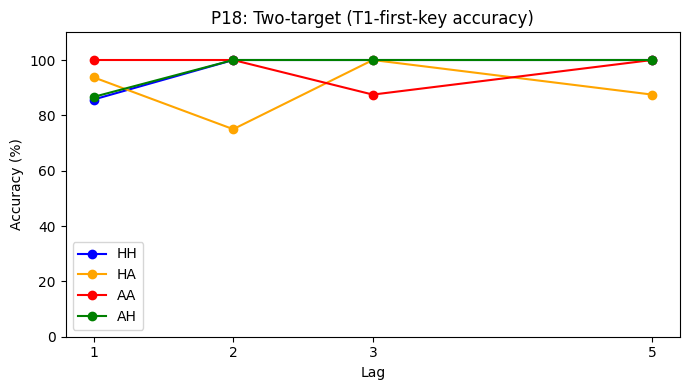

Processing P19


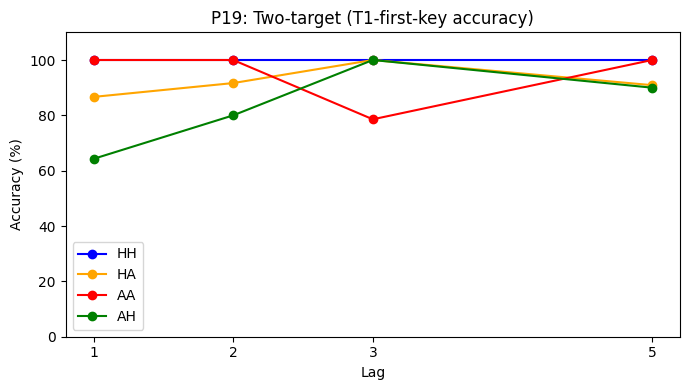

Processing P2


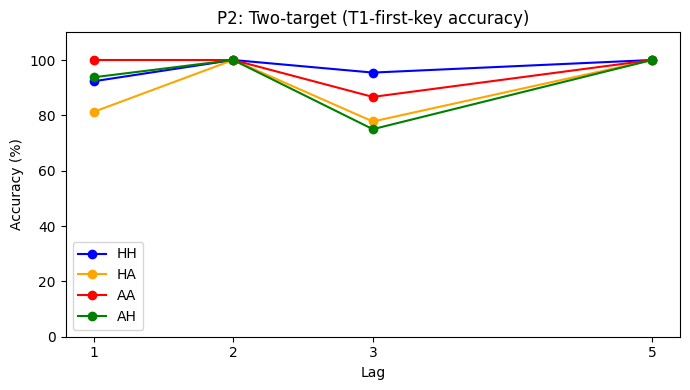

Processing P21


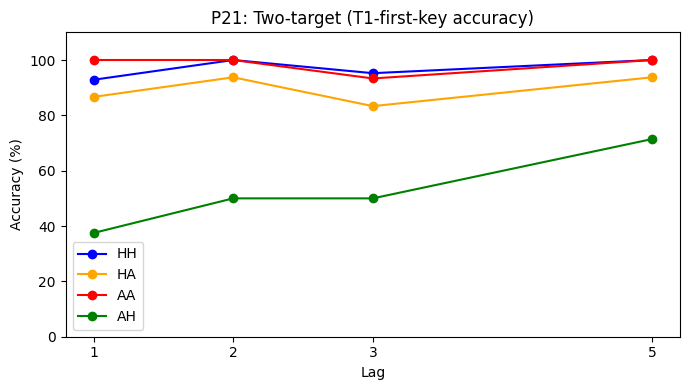

Processing P22


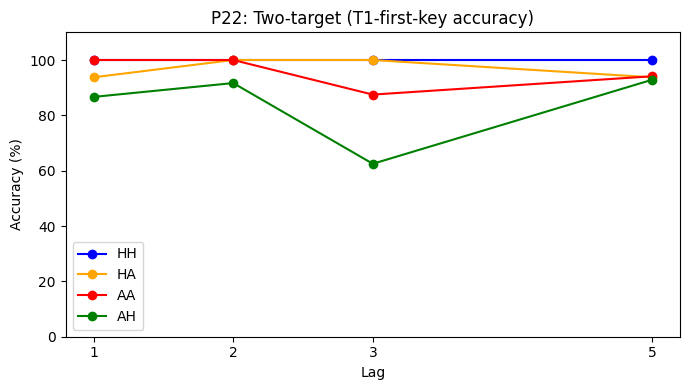

Processing P23


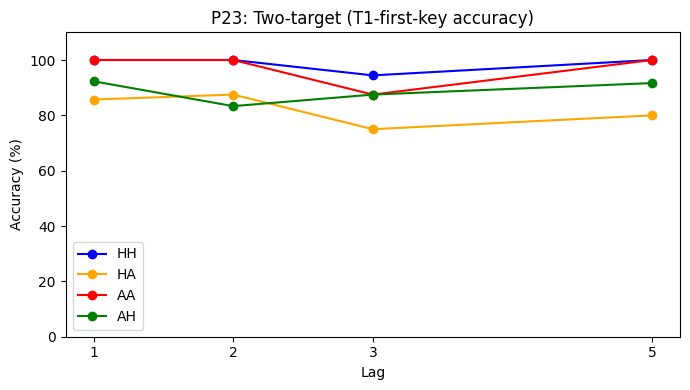

Skipping P24
Skipping P25
Processing P26


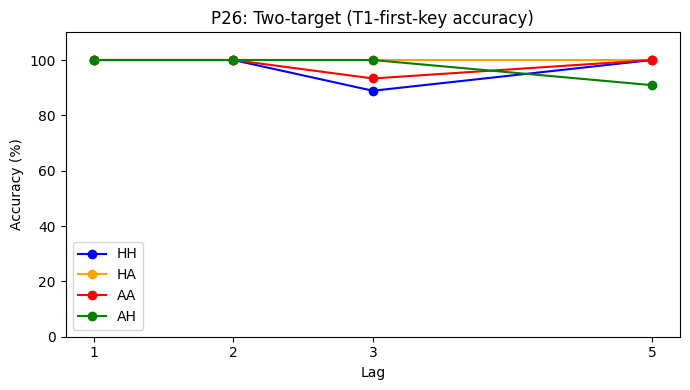

Processing P27


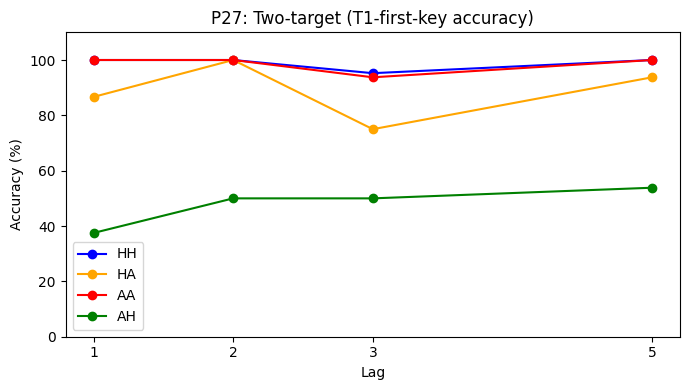

Processing P28


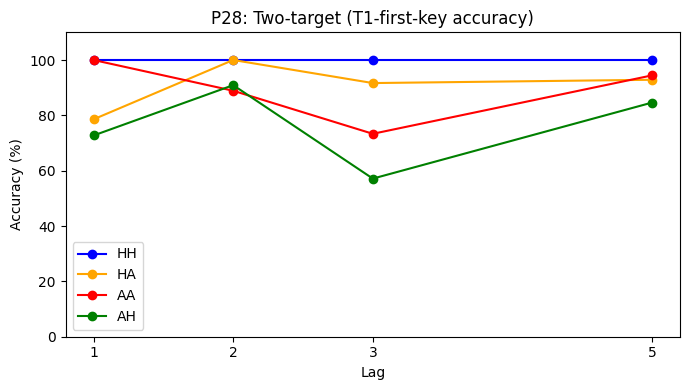

Processing P29


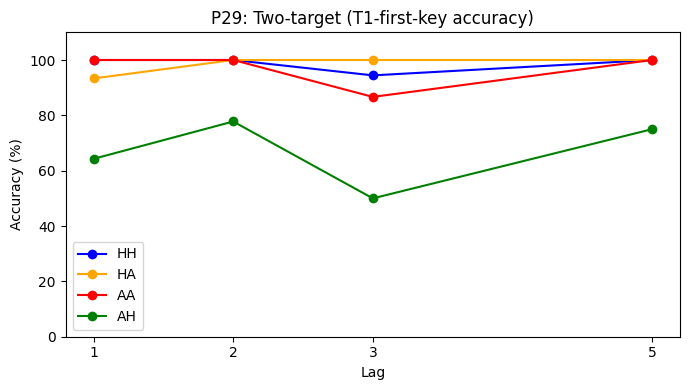

Processing P3


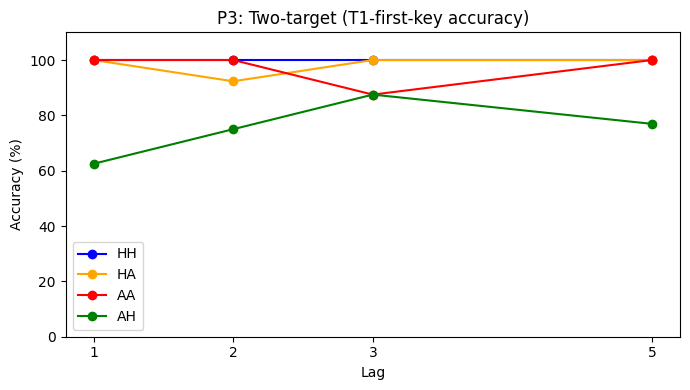

Processing P30


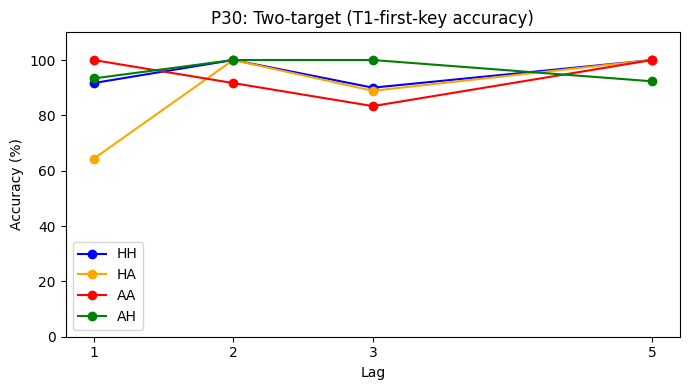

Processing P31


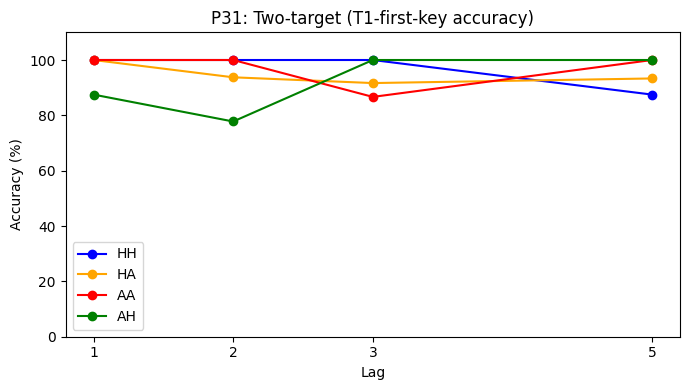

Processing P32


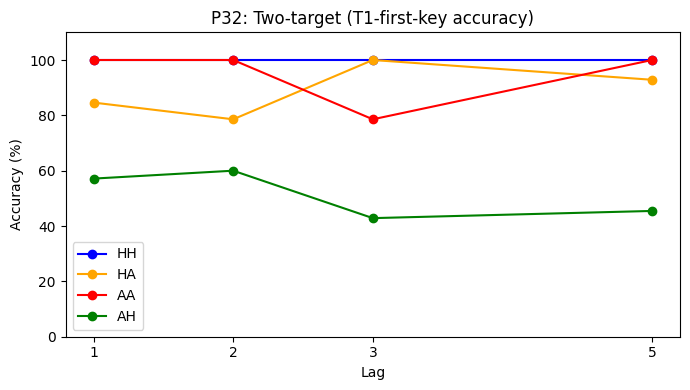

Processing P33


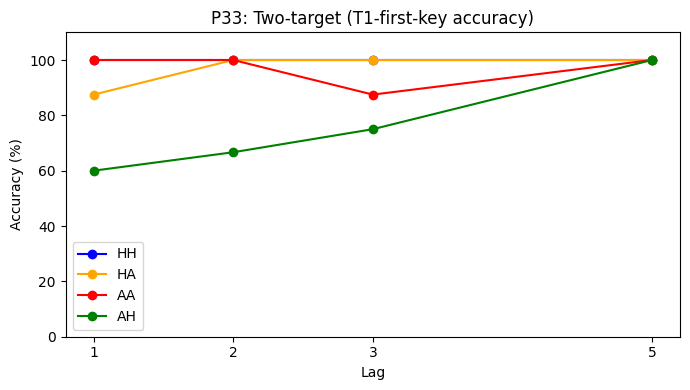

Processing P34


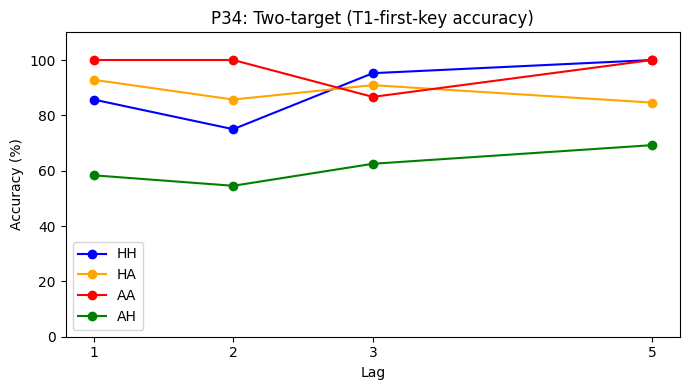

Skipping P35
Skipping P36
Processing P37


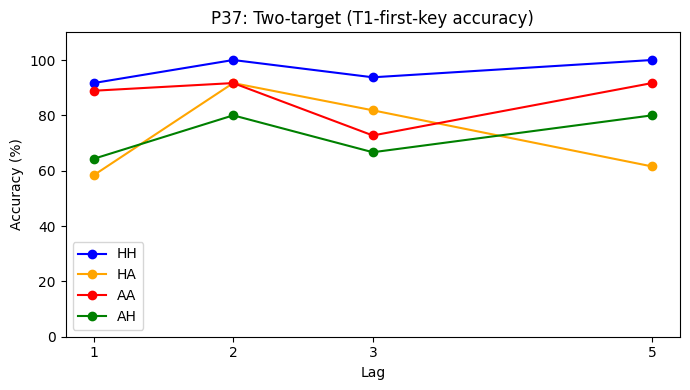

Processing P4


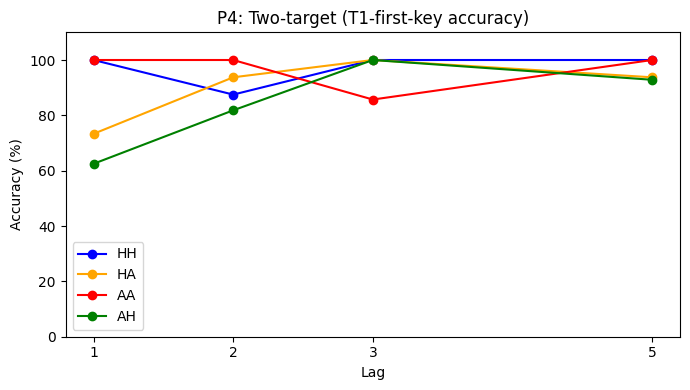

Processing P5


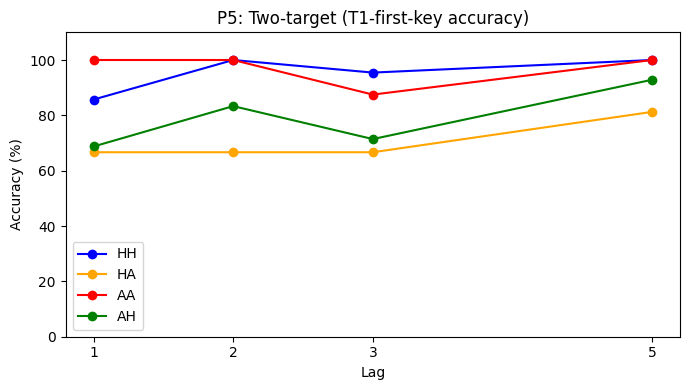

Skipping P6
Processing P7


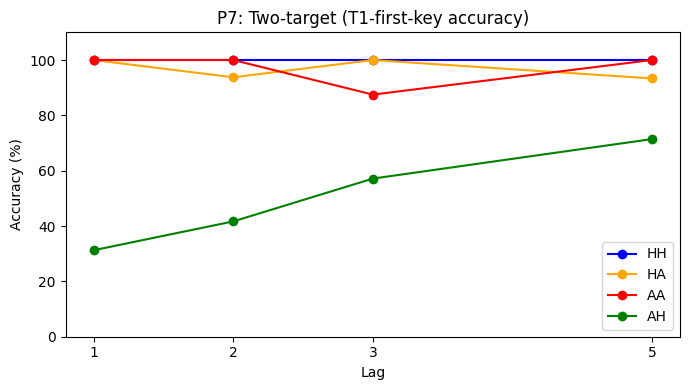

Processing P8


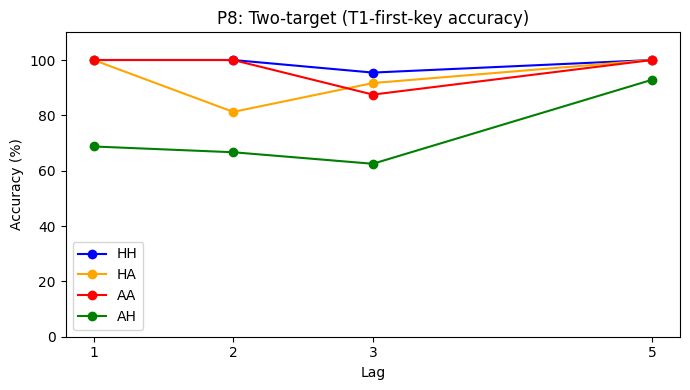

Processing P9


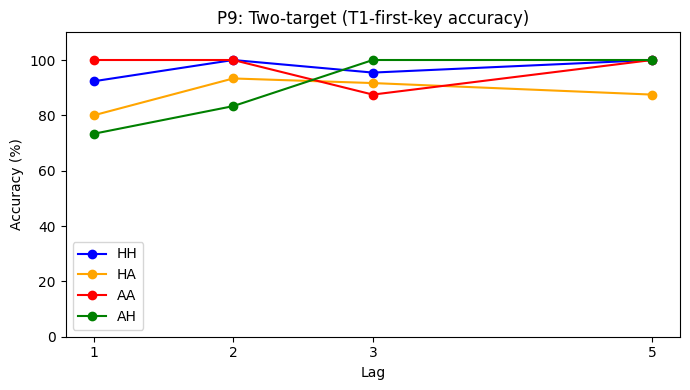


Total participants included: 32
Included IDs: ['P0', 'P1', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P2', 'P21', 'P22', 'P23', 'P26', 'P27', 'P28', 'P29', 'P3', 'P30', 'P31', 'P32', 'P33', 'P34', 'P37', 'P4', 'P5', 'P7', 'P8', 'P9']

Lag distribution per participant:
participant
P0     [1, 2, 3, 5]
P1     [1, 2, 3, 5]
P10    [1, 2, 3, 5]
P11    [1, 2, 3, 5]
P12    [1, 2, 3, 5]
P13    [1, 2, 3, 5]
P14    [1, 2, 3, 5]
P15    [1, 2, 3, 5]
P16    [1, 2, 3, 5]
P17    [1, 2, 3, 5]
P18    [1, 2, 3, 5]
P19    [1, 2, 3, 5]
P2     [1, 2, 3, 5]
P21    [1, 2, 3, 5]
P22    [1, 2, 3, 5]
P23    [1, 2, 3, 5]
P26    [1, 2, 3, 5]
P27    [1, 2, 3, 5]
P28    [1, 2, 3, 5]
P29    [1, 2, 3, 5]
P3     [1, 2, 3, 5]
P30    [1, 2, 3, 5]
P31    [1, 2, 3, 5]
P32    [1, 2, 3, 5]
P33    [1, 2, 3, 5]
P34    [1, 2, 3, 5]
P37    [1, 2, 3, 5]
P4     [1, 2, 3, 5]
P5     [1, 2, 3, 5]
P7     [1, 2, 3, 5]
P8     [1, 2, 3, 5]
P9     [1, 2, 3, 5]
Name: lag, dtype: object

Saved to: /content/drive

In [ ]:

EXCLUDE_PIDS = ["P36", "P6", "P24", "P25","P35" ]

group_HH = []
group_HA = []
group_AA = []
group_AH = []

included_pids = []

for pid, dm in sorted(all_dms.items()):

    if pid in EXCLUDE_PIDS:
        print(f"Skipping {pid}")
        continue

    print("Processing", pid)
    included_pids.append(pid)

    # --------------------------------------------------
    # Compute accuracy
    # --------------------------------------------------
    acc_HH = acc_for_pair_firstkey(dm, "HH", first_key="a")
    acc_AA = acc_for_pair_firstkey(dm, "AA", first_key="l")
    acc_HA = acc_for_pair_firstkey(dm, "HA", first_key="a")
    acc_AH = acc_for_pair_firstkey(dm, "AH", first_key="l")

    group_HH.append(acc_HH)
    group_HA.append(acc_HA)
    group_AA.append(acc_AA)
    group_AH.append(acc_AH)

    # --------------------------------------------------
    # Individual Plot
    # --------------------------------------------------
    plt.figure(figsize=(7,4))
    plt.plot(LAGS, acc_HH, marker='o', color=colors["HH"], label="HH")
    plt.plot(LAGS, acc_HA, marker='o', color=colors["HA"], label="HA")
    plt.plot(LAGS, acc_AA, marker='o', color=colors["AA"], label="AA")
    plt.plot(LAGS, acc_AH, marker='o', color=colors["AH"], label="AH")

    plt.xticks(LAGS)
    plt.ylim(0,110)
    plt.xlabel("Lag")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{pid}: Two-target (T1-first-key accuracy)")
    plt.legend()
    plt.tight_layout()
    plt.show()

print(f"\nTotal participants included: {len(included_pids)}")
print("Included IDs:", included_pids)


def mean_sem(arr_list):
    arr = np.array(arr_list, dtype=float)
    mean = np.nanmean(arr, axis=0)
    sem  = np.nanstd(arr, ddof=1, axis=0) / np.sqrt(np.sum(~np.isnan(arr), axis=0))
    return mean, sem

mean_HH, sem_HH = mean_sem(group_HH)
mean_HA, sem_HA = mean_sem(group_HA)
mean_AA, sem_AA = mean_sem(group_AA)
mean_AH, sem_AH = mean_sem(group_AH)


import pandas as pd


rows = []

for pid, acc_list in zip(included_pids, zip(group_HH, group_HA, group_AA, group_AH)):

    acc_HH, acc_HA, acc_AA, acc_AH = acc_list

    for lag_idx, lag in enumerate(LAGS):

        rows.append([pid, "HH", lag, acc_HH[lag_idx]])
        rows.append([pid, "HA", lag, acc_HA[lag_idx]])
        rows.append([pid, "AA", lag, acc_AA[lag_idx]])
        rows.append([pid, "AH", lag, acc_AH[lag_idx]])


df_long = pd.DataFrame(
    rows,
    columns=["participant", "pair", "lag", "accuracy"]
)

df_long["lag"] = pd.to_numeric(df_long["lag"], errors="coerce")


print("\nLag distribution per participant:")
print(
    df_long
    .groupby("participant")["lag"]
    .unique()
)


out_csv = "/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/trialwise_accuracy_T1_detection.csv"

df_long.to_csv(out_csv, index=False)

print("\nSaved to:", out_csv)
print(df_long.head())


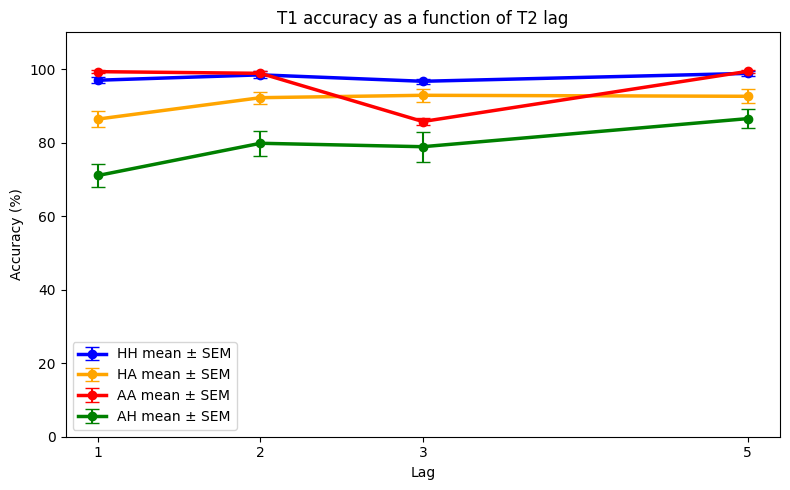

In [ ]:
# --------------------------------------------------
# GROUP PLOT
# --------------------------------------------------
plt.figure(figsize=(8,5))

for pair, m, s in zip(
    ["HH","HA","AA","AH"],
    [mean_HH, mean_HA, mean_AA, mean_AH],
    [sem_HH,  sem_HA,  sem_AA,  sem_AH]
):

    plt.errorbar(
        LAGS, m, yerr=s,
        marker='o',
        linewidth=2.5,
        elinewidth=1.5,
        capsize=5,
        label=f"{pair} mean ± SEM",
        color=colors[pair]
    )

    #plt.fill_between(LAGS, m - s, m + s, alpha=0.15, color=colors[pair])

plt.xticks(LAGS)
plt.ylim(0,110)
plt.xlabel("Lag")
plt.ylabel("Accuracy (%)")
plt.title("T1 accuracy as a function of T2 lag")
plt.legend()
plt.tight_layout()
plt.show()

## Stat on the T1 detection data

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# =====================================================
# LOAD DATA
# =====================================================
csv_path = "/content/drive/MyDrive/Maity (pupil size, attentional blink, emotional faces)/Participants_Data/trialwise_accuracy_T1_detection.csv"

df = pd.read_csv(csv_path)

# Ensure categorical
df["participant"] = df["participant"].astype(str)
df["pair"] = df["pair"].astype(str)
df["lag"] = df["lag"].astype(str)

print("\nData overview:")
print(df.head())

# =====================================================
# TWO-WAY REPEATED MEASURES ANOVA
# =====================================================
aov = AnovaRM(
    data=df,
    depvar="accuracy",
    subject="participant",
    within=["pair", "lag"]
).fit()

print("\n==============================")
print("Repeated Measures ANOVA")
print("==============================")
print(aov)

# Extract p-values
anova_table = aov.anova_table

p_pair = anova_table.loc["pair", "Pr > F"]
p_lag = anova_table.loc["lag", "Pr > F"]
p_interaction = anova_table.loc["pair:lag", "Pr > F"]

# =====================================================
# POST-HOC TESTS (ONLY IF SIGNIFICANT)
# =====================================================

alpha = 0.05

# ---- Main effect of PAIR ----
if p_pair < alpha:
    print("\nMain effect of PAIR significant → Running Tukey HSD (collapsed across lag)")

    # Collapse across lag
    df_pair_mean = (
        df.groupby(["participant", "pair"])["accuracy"]
        .mean()
        .reset_index()
    )

    tukey_pair = pairwise_tukeyhsd(
        endog=df_pair_mean["accuracy"],
        groups=df_pair_mean["pair"],
        alpha=alpha
    )
    print(tukey_pair)

# ---- Main effect of LAG ----
if p_lag < alpha:
    print("\nMain effect of LAG significant → Running Tukey HSD (collapsed across pair)")

    df_lag_mean = (
        df.groupby(["participant", "lag"])["accuracy"]
        .mean()
        .reset_index()
    )

    tukey_lag = pairwise_tukeyhsd(
        endog=df_lag_mean["accuracy"],
        groups=df_lag_mean["lag"],
        alpha=alpha
    )
    print(tukey_lag)

# ---- Interaction ----
if p_interaction < alpha:
    print("\nInteraction significant → Running Tukey on pair × lag combination")

    df["pair_lag"] = df["pair"] + "_L" + df["lag"]

    tukey_interaction = pairwise_tukeyhsd(
        endog=df["accuracy"],
        groups=df["pair_lag"],
        alpha=alpha
    )
    print(tukey_interaction)



Data overview:
  participant pair lag    accuracy
0          P0   HH   1  100.000000
1          P0   HA   1   85.714286
2          P0   AA   1  100.000000
3          P0   AH   1   86.666667
4          P0   HH   2   87.500000

Repeated Measures ANOVA
                 Anova
         F Value Num DF  Den DF  Pr > F
---------------------------------------
pair     27.0874 3.0000  93.0000 0.0000
lag      17.5732 3.0000  93.0000 0.0000
pair:lag 13.0906 9.0000 279.0000 0.0000


Main effect of PAIR significant → Running Tukey HSD (collapsed across lag)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
    AA     AH -16.7432    0.0 -22.7932 -10.6932   True
    AA     HA  -4.7905 0.1714 -10.8405   1.2594  False
    AA     HH   1.9116 0.8436  -4.1383   7.9616  False
    AH     HA  11.9526    0.0   5.9027  18.0026   True
    AH     HH  18.6548    0.0  12.6049  24.7048   True
    HA   

## Lag 1 vs Other lag

In [ ]:

print("\n====================================================")
print("Lag 1 vs Other Lags (paired t-test, Bonferroni corrected)")
print("====================================================")

for pair in pairs:

    df_pair = df[df["pair"] == pair]

    lag_data = {}

    for lag in lag_order:
        vals = (
            df_pair[df_pair["lag"] == lag]
            .sort_values("participant")["accuracy"]
            .values
        )
        lag_data[lag] = vals

    comparisons_lag1 = [(1,2), (1,3), (1,5)]
    pvals = []
    tvals = []
    effect_sizes = []

    for l1, l2 in comparisons_lag1:

        d1 = lag_data[l1]
        d2 = lag_data[l2]

        t, p = ttest_rel(d1, d2)

        # Cohen's dz for paired samples
        diff = d1 - d2
        dz = np.mean(diff) / np.std(diff, ddof=1)

        pvals.append(p)
        tvals.append(t)
        effect_sizes.append(dz)

    # Bonferroni correction
    reject, pvals_corr, _, _ = multipletests(
        pvals, method="bonferroni"
    )

    print(f"\n--- {pair} ---")

    for (l1, l2), t, p_unc, p_corr, dz in zip(
        comparisons_lag1,
        tvals,
        pvals,
        pvals_corr,
        effect_sizes
    ):
        sig = "SIGNIFICANT" if p_corr < 0.05 else "n.s."
        print(
            f"Lag {l1} vs {l2}: "
            f"t = {t:.3f}, "
            f"p-unc = {p_unc:.4f}, "
            f"p-bonf = {p_corr:.4f}, "
            f"Cohen's dz = {dz:.3f}  --> {sig}"
        )



Lag 1 vs Other Lags (paired t-test, Bonferroni corrected)

--- HH ---
Lag 1 vs 2: t = -1.340, p-unc = 0.1898, p-bonf = 0.5695, Cohen's dz = -0.237  --> n.s.
Lag 1 vs 3: t = 0.294, p-unc = 0.7705, p-bonf = 1.0000, Cohen's dz = 0.052  --> n.s.
Lag 1 vs 5: t = -1.690, p-unc = 0.1012, p-bonf = 0.3035, Cohen's dz = -0.299  --> n.s.

--- HA ---
Lag 1 vs 2: t = -2.194, p-unc = 0.0359, p-bonf = 0.1076, Cohen's dz = -0.388  --> n.s.
Lag 1 vs 3: t = -2.927, p-unc = 0.0064, p-bonf = 0.0191, Cohen's dz = -0.517  --> SIGNIFICANT
Lag 1 vs 5: t = -2.471, p-unc = 0.0192, p-bonf = 0.0575, Cohen's dz = -0.437  --> n.s.

--- AA ---
Lag 1 vs 2: t = 0.721, p-unc = 0.4764, p-bonf = 1.0000, Cohen's dz = 0.127  --> n.s.
Lag 1 vs 3: t = 15.743, p-unc = 0.0000, p-bonf = 0.0000, Cohen's dz = 2.783  --> SIGNIFICANT
Lag 1 vs 5: t = -0.172, p-unc = 0.8645, p-bonf = 1.0000, Cohen's dz = -0.030  --> n.s.

--- AH ---
Lag 1 vs 2: t = -4.483, p-unc = 0.0001, p-bonf = 0.0003, Cohen's dz = -0.792  --> SIGNIFICANT
Lag 1 v

In [ ]:
from scipy.stats import ttest_rel
import numpy as np

print("\n====================================================")
print("Lag 1 vs Combined Other Lags (Collapsed Across Emotion)")
print("====================================================")

# Collapse across emotion first
df_collapsed = (
    df.groupby(["participant", "lag"])["accuracy"]
    .mean()
    .reset_index()
)

# Compute participant means
lag1_vals = (
    df_collapsed[df_collapsed["lag"] == 1]
    .sort_values("participant")["accuracy"]
    .values
)

lag_other_vals = (
    df_collapsed[df_collapsed["lag"].isin([2,3,5])]
    .groupby("participant")["accuracy"]
    .mean()
    .sort_index()
    .values
)

t, p = ttest_rel(lag1_vals, lag_other_vals)

# Cohen's dz
diff = lag1_vals - lag_other_vals
dz = np.mean(diff) / np.std(diff, ddof=1)

print(f"t = {t:.3f}")
print(f"p = {p:.4f}")
print(f"Cohen's dz = {dz:.3f}")



Lag 1 vs Combined Other Lags (Collapsed Across Emotion)
t = -3.662
p = 0.0009
Cohen's dz = -0.647
